# Missing Data Analysis — Part 2A · Severity Analysis
## Stage 2 · Full simulation, performance tables, severity figures

**Author:** Purbasa Bhaduri · M.Sc. Statistics, St. Xavier's University, Kolkata

---

### Where we are
Stage 1 built and tested the toolbox (36/36 checks passed) and ran a 40-replicate pilot. **Stage 2 is the real experiment**: about a thousand replicate datasets, every mechanism, every severity level, every method, with bootstrap or Rubin intervals, so that we can finally measure **bias, RMSE, 95% coverage, interval width and SE calibration — each with its Monte Carlo error**.

| Section | What happens | Runtime (rough) |
|---|---|---|
| **8** | Settings, toolbox check, speed test, **the full simulation** (parallel, checkpointed to Google Drive, resumable), integrity checks | the long part (tens of minutes to ~1.5 h) |
| **9** | Performance tables per mechanism and severity, with Monte Carlo errors; the intercept (β₀) for MNAR; expectation checks | seconds |
| **10** | Severity figures: one 6-panel dashboard per mechanism + a headline coverage figure | seconds |
| **11** | **MNAR_mild** sensitivity run (selection strength 0.5, the strength Part 1 used) | about a third of Section 8 |
| **12** | Report card, export everything as one zip (downloads automatically) | seconds |

### Before you press anything
1. **Upload `sim_toolbox.py`** (from the Stage 1 zip, folder `code/`) into the Colab file panel (📁 on the left), or just run Section 8.2 and it will ask you for the file. The notebook checks that it is the *exact* Stage 1 file (by fingerprint), so the protocol cannot drift.
2. **Keep the browser tab open** during Section 8. If Colab disconnects, nothing is lost: results are saved to your Google Drive in small chunks. Reconnect, run Sections **8.1 → 8.4** again, and the run **resumes from the last finished chunk**.
3. Run the cells **one by one, top to bottom**. Every check prints PASS or FAIL.

### A promise about honesty
Some patterns will confirm theory (Complete Case is unbiased when missingness depends only on X₁), others may surprise us. Both get reported. A FAIL in an *expectation check* is not a crash — it is a finding to investigate, and I will treat it as one.

---
## Section 8 · The full simulation

### 8.1 Imports, run settings and Google Drive
Everything you might want to change is inside the block marked **RUN SETTINGS**.

| Setting | Default | Meaning |
|---|---|---|
| `R_TARGET` | 1000 | replicate datasets per mechanism. Monte Carlo SE of a coverage estimate is $\sqrt{0.95\cdot 0.05/R}\approx 0.7\%$ at $R=1000$ |
| `CHUNK` | 25 | replicates saved per checkpoint file (`R_TARGET` must be a multiple) |
| `BOOT_B` | 200 | bootstrap resamples per method per condition (the protocol value) |
| `N_JOBS` | `"auto"` | CPU cores. `"auto"` runs a short speed test (Section 8.3) and picks the faster option |
| `MAX_MINUTES` | `None` | optional: stop *gracefully* after this many minutes (re-run Section 8.4 to continue) |
| `RUN_MILD` | `True` | run the MNAR_mild sensitivity analysis (Section 11) |
| `USE_DRIVE` | `True` | save checkpoints to Google Drive (strongly recommended) |

**Extending later is free.** Because replicate *r* depends only on `(seed, r)`, you can raise `R_TARGET` from 1000 to 2000 later and the notebook will simply compute replicates 1000–1999 and append them.

In [1]:
# 8.1  Imports, run settings, Google Drive
import os, sys, time, json, shutil, hashlib, platform, importlib, warnings, zipfile
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
try:
    from IPython.display import display, Markdown
except ImportError:
    display, Markdown = print, str
warnings.filterwarnings("ignore")

# ------------------------------ RUN SETTINGS (edit here only) ------------------------------
R_TARGET     = 1000                  # replicates per mechanism (multiple of CHUNK)
CHUNK        = 25                    # replicates per checkpoint file
BOOT_B       = 200                   # bootstrap resamples (protocol value)
N_JOBS       = "auto"                # "auto" or an integer number of cores
MAX_MINUTES  = None                  # e.g. 50 -> stop gracefully after 50 min, resume by re-running 8.4
RUN_MILD     = True                  # MNAR_mild sensitivity run (Section 11)
USE_DRIVE    = True                  # checkpoint to Google Drive
DRIVE_DIR    = "/content/drive/MyDrive/MissingData_Part2A_Stage2"
OUT          = "part2A_stage2_outputs"   # everything in here is zipped at the end
ALLOW_TOOLBOX_MISMATCH = False       # keep False: refuse to run with a modified toolbox
# --------------------------------------------------------------------------------------------
assert R_TARGET % CHUNK == 0, "R_TARGET must be a multiple of CHUNK"

# make the toolbox importable (also inside parallel worker processes)
sys.dont_write_bytecode = True
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
os.environ["PYTHONPATH"] = os.getcwd() + os.pathsep + os.environ.get("PYTHONPATH", "")

# Google Drive (only exists inside Colab)
IN_COLAB = "google.colab" in sys.modules
STORE = "local_store"                # where chunks / toolbox backup live
if USE_DRIVE and IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        STORE = DRIVE_DIR
        print("Google Drive mounted. Checkpoints will be saved in:", STORE)
    except Exception as e:
        print("!! Could not mount Google Drive (", e, ")\n!! Falling back to local storage: a disconnect WOULD lose progress.")
elif USE_DRIVE:
    print("Not running in Colab: using local folder", STORE)
os.makedirs(STORE, exist_ok=True)
for sub in ["figures", "results", "results/tables", "data", "code"]:
    os.makedirs(f"{OUT}/{sub}", exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#555555",
                     "axes.labelcolor": "#333333", "xtick.color": "#444444", "ytick.color": "#444444"})

# The logbook: every check records PASS / FAIL here (summarised in Section 12)
TESTS = []
def record(section, check, passed, detail=""):
    TESTS.append({"section": section, "check": check, "result": "PASS" if passed else "FAIL", "detail": detail})
    print(("PASS  " if passed else "FAIL  ") + f"[{section}] {check}" + (f"  ->  {detail}" if detail else ""))

def reload_toolbox():
    importlib.invalidate_caches()
    import sim_toolbox
    return importlib.reload(sim_toolbox)

print("\nPython :", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)
print("Cores  :", os.cpu_count(), "| Run date:", time.strftime("%Y-%m-%d %H:%M"))

Mounted at /content/drive
Google Drive mounted. Checkpoints will be saved in: /content/drive/MyDrive/MissingData_Part2A_Stage2

Python : 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | scipy 1.16.3 | matplotlib 3.10.0
Cores  : 2 | Run date: 2026-10-11 16:51


### 8.2 Find, verify and load the toolbox
This cell looks for `sim_toolbox.py` in (1) the working folder, (2) the backup copy in your Drive folder, and otherwise (3) asks you to upload it. It then compares a **SHA-256 fingerprint** with the Stage 1 file. If you accidentally edited the toolbox, the fingerprint differs and the notebook refuses to continue: a simulation study must not silently change its own protocol halfway.

A copy is saved to Drive so that after a disconnect you don't have to upload it again.

In [2]:
# 8.2  Locate, verify (fingerprint) and import the toolbox
STAGE1_SHA256 = "e873779edce0eb9dcacda759f6dc375c6d855411864406c8ebb074b3c0974d22"

def file_sha256(path):
    return hashlib.sha256(open(path, "rb").read().replace(b"\r\n", b"\n")).hexdigest()

def ensure_toolbox():
    if os.path.exists("sim_toolbox.py"):
        return "found in the working folder"
    backup = f"{STORE}/sim_toolbox.py"
    if os.path.exists(backup):
        shutil.copy(backup, "sim_toolbox.py")
        return "restored from the Drive backup"
    if IN_COLAB:
        from google.colab import files
        print("Please upload sim_toolbox.py (Stage 1 zip -> code/sim_toolbox.py) ...")
        up = files.upload()
        for name in up:
            if name.lower().startswith("sim_toolbox") and name.endswith(".py"):
                shutil.move(name, "sim_toolbox.py")
        if os.path.exists("sim_toolbox.py"):
            return "uploaded just now"
    raise FileNotFoundError("sim_toolbox.py not found. Upload it from the Stage 1 zip (code/sim_toolbox.py) "
                            "into the working folder and re-run this cell.")

where = ensure_toolbox()
TOOLBOX_SHA = file_sha256("sim_toolbox.py")
print(f"Toolbox {where}.")
print("fingerprint :", TOOLBOX_SHA)
print("Stage 1     :", STAGE1_SHA256)
if TOOLBOX_SHA != STAGE1_SHA256 and not ALLOW_TOOLBOX_MISMATCH:
    raise RuntimeError("sim_toolbox.py differs from the Stage 1 toolbox. Upload the original file "
                       "(or, if you changed it on purpose, set ALLOW_TOOLBOX_MISMATCH = True and tell me).")
record("8", "Toolbox is byte-identical to the Stage 1 toolbox (SHA-256)", TOOLBOX_SHA == STAGE1_SHA256)
shutil.copy("sim_toolbox.py", f"{STORE}/sim_toolbox.py")          # backup for resuming after a disconnect

tb = reload_toolbox()
protocol_ok = (tb.N == 100 and list(tb.SEVERITY_LEVELS) == [10, 20, 30, 40, 50]
               and tb.MAIN_MECHANISMS == ["MCAR", "MAR", "MNAR"] and len(tb.METHODS) == 7
               and tb.MICE_M == 20 and tb.PMM_K == 5 and tb.MASTER_SEED == 42
               and list(tb.BETA_TRUE) == [5.0, 2.0, -1.5, 1.0]
               and tb.MECH_SPECS["MNAR"]["slope"] == 1.0 and tb.MECH_SPECS["MNAR_mild"]["slope"] == 0.5)
record("8", "Protocol constants are the agreed ones (n=100, 10-50%, 7 methods, m=20, k=5, seed 42, slopes 1.0/0.5)", protocol_ok)

# determinism smoke test: the same replicate twice must give identical rows
r1 = pd.DataFrame(tb.run_replicate(3, mechanisms=["MCAR"], levels=[20], boot_B=15, mice_m=4))
r2 = pd.DataFrame(tb.run_replicate(3, mechanisms=["MCAR"], levels=[20], boot_B=15, mice_m=4))
record("8", "A replicate is exactly reproducible (same inputs -> identical rows)", r1.equals(r2))
ROWS_PER_REP_MAIN = 1 + len(tb.MAIN_MECHANISMS) * len(tb.SEVERITY_LEVELS) * len(tb.METHODS)
record("8", "Main run produces 106 rows per replicate", ROWS_PER_REP_MAIN == 106, f"{ROWS_PER_REP_MAIN}")

Toolbox found in the working folder.
fingerprint : e873779edce0eb9dcacda759f6dc375c6d855411864406c8ebb074b3c0974d22
Stage 1     : e873779edce0eb9dcacda759f6dc375c6d855411864406c8ebb074b3c0974d22
PASS  [8] Toolbox is byte-identical to the Stage 1 toolbox (SHA-256)
PASS  [8] Protocol constants are the agreed ones (n=100, 10-50%, 7 methods, m=20, k=5, seed 42, slopes 1.0/0.5)
PASS  [8] A replicate is exactly reproducible (same inputs -> identical rows)
PASS  [8] Main run produces 106 rows per replicate  ->  106


### 8.3 Speed test: how many cores should we really use?
Your Stage 1 projection assumed that two cores run twice as fast as one. Your pilot's *own* clock said otherwise: 40 replicates took 185 s in parallel, i.e. about **4.6 s per replicate of wall time**, whereas one core alone needed about **4.0 s**. So on that machine, parallel was **not** faster, and the "33 minutes for 1000 replicates" projection was too optimistic (the pilot itself implies roughly **75 minutes**).

Rather than guess, this cell **measures**: it times a couple of replicates on one core and a few in parallel (using replicate ids ≥ 1,000,000 that are not part of the study), then picks the faster setting. It takes under a minute.

In [3]:
# 8.3  Measure throughput (1 core vs all cores) and choose N_JOBS
from joblib import Parallel, delayed

cores = os.cpu_count() or 1
BENCH_BASE = 1_000_000                       # replicate ids that are NOT part of the study

t0 = time.time()
for r in range(BENCH_BASE, BENCH_BASE + 2):
    tb.run_replicate(r, mechanisms=tb.MAIN_MECHANISMS, boot_B=BOOT_B)
seq_rate = 2 / (time.time() - t0)            # replicates per second, one core

bench = [{"setting": "1 core", "n_jobs": 1, "reps_per_sec": seq_rate}]
if cores > 1:
    par = Parallel(n_jobs=cores)
    par(delayed(tb.n_missing_for)(10) for _ in range(cores))          # warm-up: start workers, import toolbox
    t0 = time.time()
    par(delayed(tb.run_replicate)(r, mechanisms=tb.MAIN_MECHANISMS, boot_B=BOOT_B)
        for r in range(BENCH_BASE + 10, BENCH_BASE + 10 + 2 * cores))
    bench.append({"setting": f"{cores} cores (parallel)", "n_jobs": cores,
                  "reps_per_sec": 2 * cores / (time.time() - t0)})
bench = pd.DataFrame(bench)
bench["sec_per_replicate"] = 1 / bench["reps_per_sec"]
bench["main run (min)"] = R_TARGET * bench["sec_per_replicate"] / 60
bench["MNAR_mild run (min)"] = bench["main run (min)"] / 3        # one mechanism instead of three
display(bench.round(2))

N_JOBS_USED = int(bench.loc[bench["reps_per_sec"].idxmax(), "n_jobs"]) if N_JOBS == "auto" else int(N_JOBS)
est = bench.loc[bench["n_jobs"] == N_JOBS_USED, "main run (min)"]
print(f"\nUsing N_JOBS = {N_JOBS_USED}.")
if len(est):
    print(f"Expected time for the main run (R = {R_TARGET}, B = {BOOT_B}): about {est.iloc[0]:.0f} minutes "
          f"(+ about {est.iloc[0]/3:.0f} min for MNAR_mild).")

,setting,n_jobs,reps_per_sec,sec_per_replicate,main run (min),MNAR_mild run (min)
0,1 core,1,0.11,8.96,149.31,49.77
1,2 cores (parallel),2,0.16,6.33,105.54,35.18



Using N_JOBS = 2.
Expected time for the main run (R = 1000, B = 200): about 106 minutes (+ about 35 min for MNAR_mild).


### 8.4 The simulation engine: chunked, checkpointed, resumable
**How it works**

* Replicates are grouped into **chunks** of `CHUNK` replicates. A chunk is computed (in parallel over its replicates) and then written to one CSV file in your Drive folder. The write is *atomic* (temp file, then rename), so a disconnect in the middle can never leave a half-written file that looks finished.
* On every start the engine looks at the folder, validates each chunk file (right number of rows, right replicate ids) and computes only what is missing. **That is the entire resume mechanism**, and it is safe *because* replicate *r* depends only on `(seed, r)`, not on order or core count.
* A **manifest** (toolbox fingerprint, seed, B, m, levels, methods, chunk size) is stored beside the chunks. If you later resume with different settings the engine stops instead of mixing incompatible results.
* You can stop it any time with the ⏹ button: finished chunks are kept.

Progress lines show the chunk just saved, how long it took, and a time-to-finish estimate.

In [4]:
# 8.4a  Engine (definitions only; nothing runs yet)
def rows_per_rep(mechs):
    return 1 + len(mechs) * len(tb.SEVERITY_LEVELS) * len(tb.METHODS)

def make_manifest(mechs):
    m = {"toolbox_sha256": TOOLBOX_SHA, "master_seed": tb.MASTER_SEED, "n": tb.N, "boot_B": BOOT_B,
         "mice_m": tb.MICE_M, "pmm_k": tb.PMM_K, "levels": list(tb.SEVERITY_LEVELS),
         "methods": list(tb.METHODS), "mechanisms": {k: tb.MECH_SPECS[k] for k in mechs}, "chunk": CHUNK}
    return json.loads(json.dumps(m))                       # normalise (tuples -> lists etc.)

def chunk_file(folder, tag, c):
    return f"{folder}/{tag}_chunk_{c:04d}.csv"

def chunk_is_complete(path, c, mechs):
    """A chunk counts as done only if it has exactly the expected rows and replicate ids."""
    if not os.path.exists(path):
        return False
    try:
        d = pd.read_csv(path, usecols=["rep"])
    except Exception:
        return False
    return (len(d) == CHUNK * rows_per_rep(mechs) and d["rep"].min() == c * CHUNK
            and d["rep"].max() == (c + 1) * CHUNK - 1 and d["rep"].nunique() == CHUNK)

def prepare_folder(tag, mechs):
    folder = f"{STORE}/{tag}_chunks"
    os.makedirs(folder, exist_ok=True)
    mpath, new = f"{folder}/manifest.json", make_manifest(mechs)
    if os.path.exists(mpath):
        old = json.load(open(mpath))
        diff = [k for k in new if old.get(k) != new[k]]
        if diff:
            raise RuntimeError(f"Existing results in {folder} were made with different settings ({diff}). "
                               "Restore the old settings, or move/delete that folder to start fresh.")
    else:
        json.dump(new, open(mpath, "w"), indent=1)
    return folder

def fmt_min(s):
    return f"{s/60:5.1f} min"

def run_simulation(tag, mechs, r_target=None):
    """Compute every missing chunk for this run. Returns True when all chunks exist."""
    r_target = r_target or R_TARGET
    folder, n_chunks = prepare_folder(tag, mechs), r_target // CHUNK
    todo = [c for c in range(n_chunks) if not chunk_is_complete(chunk_file(folder, tag, c), c, mechs)]
    print(f"[{tag}] mechanisms {mechs} | {n_chunks - len(todo)} of {n_chunks} chunks already finished "
          f"({(n_chunks - len(todo)) * CHUNK} of {r_target} replicates) | cores: {N_JOBS_USED}")
    if not todo:
        print(f"[{tag}] nothing to do - all chunks are present.")
        return True
    t_start, pool = time.time(), Parallel(n_jobs=N_JOBS_USED)
    try:
        for j, c in enumerate(todo):
            t_chunk = time.time()
            reps = range(c * CHUNK, (c + 1) * CHUNK)
            out = pool(delayed(tb.run_replicate)(r, mechanisms=mechs, boot_B=BOOT_B) for r in reps)
            df = pd.DataFrame([row for rows in out for row in rows])
            path = chunk_file(folder, tag, c)
            df.to_csv(path + ".tmp", index=False, float_format="%.10g")
            os.replace(path + ".tmp", path)                                   # atomic publish
            dt, elapsed = time.time() - t_chunk, time.time() - t_start
            with open(f"{folder}/timing_log.csv", "a") as f:
                f.write(f"{c},{dt:.2f},{N_JOBS_USED}\n")
            eta = elapsed / (j + 1) * (len(todo) - j - 1)
            print(f"  chunk {c + 1:>3}/{n_chunks} saved | reps {reps[0]:>4}-{reps[-1]:<4} | {dt:5.0f} s "
                  f"| elapsed {fmt_min(elapsed)} | finish in ~{fmt_min(eta)} | {100 * (n_chunks - len(todo) + j + 1) / n_chunks:5.1f}% done")
            if MAX_MINUTES and elapsed / 60 > MAX_MINUTES and j < len(todo) - 1:
                print(f"\nMAX_MINUTES reached - stopped cleanly. Re-run this cell to continue.")
                return False
    except KeyboardInterrupt:
        print("\nInterrupted. All finished chunks are safe; re-run this cell to continue.")
        return False
    print(f"[{tag}] finished: {len(todo)} chunk(s) computed in {fmt_min(time.time() - t_start)}.")
    return True

def load_chunks(tag, mechs, r_target=None):
    r_target = r_target or R_TARGET
    folder, parts = f"{STORE}/{tag}_chunks", []
    for c in range(r_target // CHUNK):
        p = chunk_file(folder, tag, c)
        if not chunk_is_complete(p, c, mechs):
            raise RuntimeError(f"Chunk {c} of run '{tag}' is missing or incomplete - run the simulation cell again.")
        parts.append(pd.read_csv(p))
    return pd.concat(parts, ignore_index=True)

print("Engine ready.")

Engine ready.


### 8.4b ▶ Run the main simulation (MCAR, MAR, MNAR)
This is the long cell. Leave the tab open. If it stops for any reason (disconnect, ⏹, `MAX_MINUTES`), **just run Sections 8.1 → 8.4 again**: the finished chunks are recognised and skipped.

In [5]:
# 8.4b  Run the main simulation (resumable - safe to run again after any interruption)
MAIN_DONE = run_simulation("main", tb.MAIN_MECHANISMS)

[main] mechanisms ['MCAR', 'MAR', 'MNAR'] | 0 of 40 chunks already finished (0 of 1000 replicates) | cores: 2
  chunk   1/40 saved | reps    0-24   |   156 s | elapsed   2.6 min | finish in ~101.6 min |   2.5% done
  chunk   2/40 saved | reps   25-49   |   158 s | elapsed   5.2 min | finish in ~ 99.5 min |   5.0% done
  chunk   3/40 saved | reps   50-74   |   195 s | elapsed   8.5 min | finish in ~104.8 min |   7.5% done
  chunk   4/40 saved | reps   75-99   |   169 s | elapsed  11.3 min | finish in ~101.8 min |  10.0% done
  chunk   5/40 saved | reps  100-124  |   134 s | elapsed  13.5 min | finish in ~ 94.8 min |  12.5% done
  chunk   6/40 saved | reps  125-149  |   131 s | elapsed  15.7 min | finish in ~ 89.1 min |  15.0% done
  chunk   7/40 saved | reps  150-174  |   132 s | elapsed  17.9 min | finish in ~ 84.5 min |  17.5% done
  chunk   8/40 saved | reps  175-199  |   131 s | elapsed  20.1 min | finish in ~ 80.4 min |  20.0% done
  chunk   9/40 saved | reps  200-224  |   130 s | 

### 8.5 Assemble the results and verify their integrity
Before analysing anything we check that the assembled table is **complete, clean and genuinely reproducible**:

| Check | Why |
|---|---|
| exactly $R \times 106$ rows, every condition has every replicate once | no chunk lost or duplicated |
| no missing values, positive SEs and interval widths, `n_missing` = severity | clean output |
| Complete Case = Regression Imputation = EM (estimates **and** intervals) | the known identity when only $Y$ is missing; also lets us draw the three as **one** line later |
| EM converged everywhere | no run hit the iteration cap |
| **Re-computation spot check**: replicates 0, middle and last are recomputed from scratch and must equal the stored rows | proves the chunk files are exactly what the toolbox produces |

In [6]:
# 8.5  Assemble and verify
if not MAIN_DONE:
    raise RuntimeError("The main simulation is not finished yet - run cell 8.4b again until it reports 'finished'.")
raw = load_chunks("main", tb.MAIN_MECHANISMS)
KEYS = ["mechanism", "severity", "method"]
NUM = ["b0", "b1", "b2", "b3", "se_b1", "ci_lo", "ci_hi"]
R = int(raw["rep"].nunique())
print(f"Loaded {len(raw):,} rows x {raw.shape[1]} columns  |  {R} replicates  |  {raw.groupby(KEYS).ngroups} conditions")

record("8.5", f"Row count = {R} replicates x 106 rows", len(raw) == R * ROWS_PER_REP_MAIN, f"{len(raw):,} rows")
sizes = raw.groupby(KEYS).size()
record("8.5", "Every condition (mechanism x severity x method) has every replicate exactly once",
       bool((sizes == R).all()) and raw.duplicated(["rep"] + KEYS).sum() == 0 and sorted(raw["rep"].unique()) == list(range(R)),
       f"{len(sizes)} conditions x {R}")
record("8.5", "No missing values in estimates, SEs or interval limits", bool(raw[NUM].notna().all().all()))
record("8.5", "All SEs and interval widths are positive", bool((raw["se_b1"] > 0).all() and (raw["ci_hi"] > raw["ci_lo"]).all()))
record("8.5", "n_missing equals the severity level in every row (exact deletion)",
       bool((raw["n_missing"] == raw["severity"]).all()))

# Complete Case = Regression Imputation = EM
piv = raw.pivot_table(index=["rep", "mechanism", "severity"], columns="method", values=NUM, aggfunc="first")
trio = ["Complete Case", "Regression Imputation", "EM"]
worst = max(float((piv[(c, trio[0])] - piv[(c, m)]).abs().max()) for c in NUM for m in trio[1:])
TRIO_IDENTICAL = worst < 1e-6
record("8.5", "Complete Case = Regression Imputation = EM (all coefficients, SEs and intervals)", TRIO_IDENTICAL,
       f"max difference {worst:.1e}")
em = raw[raw["method"] == "EM"]["em_iters"]
record("8.5", "EM converged below the iteration cap in every run", bool(em.max() < tb.EM_MAXIT),
       f"max {int(em.max())} iterations; average {em.mean():.0f}")

# recompute three replicates from scratch and compare with what was stored
def compare_replicate(r):
    fresh = pd.DataFrame(tb.run_replicate(r, mechanisms=tb.MAIN_MECHANISMS, boot_B=BOOT_B)).set_index(["rep"] + KEYS).sort_index()
    stored = raw[raw["rep"] == r].set_index(["rep"] + KEYS).sort_index()
    cols = NUM + ["n_missing", "em_iters", "mice_df"]
    return max(float(np.nanmax(np.abs(fresh[c].to_numpy(float) - stored[c].to_numpy(float)))) for c in cols)

spot = sorted({0, R // 2, R - 1})
diffs = [compare_replicate(r) for r in spot]
record("8.5", f"Replicates {spot} recomputed from scratch equal the stored results", max(diffs) < 1e-7,
       f"max difference {max(diffs):.1e}")

Loaded 106,000 rows x 14 columns  |  1000 replicates  |  106 conditions
PASS  [8.5] Row count = 1000 replicates x 106 rows  ->  106,000 rows
PASS  [8.5] Every condition (mechanism x severity x method) has every replicate exactly once  ->  106 conditions x 1000
PASS  [8.5] No missing values in estimates, SEs or interval limits
PASS  [8.5] All SEs and interval widths are positive
PASS  [8.5] n_missing equals the severity level in every row (exact deletion)
PASS  [8.5] Complete Case = Regression Imputation = EM (all coefficients, SEs and intervals)  ->  max difference 1.6e-07
PASS  [8.5] EM converged below the iteration cap in every run  ->  max 156 iterations; average 34
PASS  [8.5] Replicates [0, 500, 999] recomputed from scratch equal the stored results  ->  max difference 4.9e-09


### 8.6 How long did it really take?
A short compute-time summary from the chunk timing logs (saved for the write-up: "the simulation took X core-hours").

In [7]:
# 8.6  Compute-time summary from the chunk logs
def timing_summary(tag):
    p = f"{STORE}/{tag}_chunks/timing_log.csv"
    if not os.path.exists(p):
        return None
    t = pd.read_csv(p, header=None, names=["chunk", "seconds", "n_jobs"]).drop_duplicates("chunk", keep="last")
    return {"chunks_timed": int(len(t)), "wall_minutes": round(float(t["seconds"].sum()) / 60, 1),
            "sec_per_replicate_wall": round(float(t["seconds"].sum()) / (len(t) * CHUNK), 2)}

TIMING = {"main": timing_summary("main")}
print("Main run timing:", TIMING["main"] or "(no log: chunks were computed before logging started)")

Main run timing: {'chunks_timed': 40, 'wall_minutes': 93.4, 'sec_per_replicate_wall': 5.6}


---
## Section 9 · Performance tables

### 9.1 The performance measures, with Monte Carlo error
For each condition (mechanism × severity × method) we have $R$ estimates $\hat\beta^{(1)},\dots,\hat\beta^{(R)}$ of a coefficient with true value $\beta$. We summarise them as follows, and — because every number comes from a finite simulation — attach a **Monte Carlo standard error (MC SE)** to each.

| Measure | Definition | MC SE |
|---|---|---|
| **Bias** | $\frac1R\sum(\hat\beta^{(r)}-\beta)$ | $s/\sqrt R$ |
| **Empirical SD** | SD of the $\hat\beta^{(r)}$ — the *true* sampling variability of the method | $s/\sqrt{2(R-1)}$ |
| **RMSE** | $\sqrt{\frac1R\sum(\hat\beta^{(r)}-\beta)^2}$ — bias and variability together | delta method |
| **Average SE** | $\sqrt{\text{mean of the reported }SE^2}$ | — |
| **SE ratio** | average SE ÷ empirical SD. **1 = honest standard errors**; < 1 overconfident; > 1 conservative | jackknife |
| **Coverage** | share of the $R$ intervals that contain $\beta$ (target 95%) | $\sqrt{p(1-p)/R}$ |
| **Width** | mean length of the 95% interval | $s_w/\sqrt R$ |
| **Miss-low / Miss-high** | share of intervals lying entirely *below* / *above* the truth — tells us **which direction** a failing method fails in | $\sqrt{p(1-p)/R}$ |

**Two things worth understanding.**
* *Bias and SE ratio measure different failures.* A method can have perfectly honest SEs (ratio ≈ 1) and still miss the truth if it is biased — that is exactly what coverage reveals. Under MNAR we expect this combination.
* *The intercept.* Only $\beta_1$ has a stored SE and interval, so **coverage, SE ratio and width exist only for $\beta_1$**. For $\beta_0,\dots,\beta_3$ we report bias, empirical SD and RMSE. (This is also why I do **not** call the toolbox's `summarise_results` with `coef="b0"`: it would compare $\beta_1$'s interval with $\beta_0$'s truth and report a meaningless coverage of 0. Our own function below refuses to do that, and we check it against the toolbox for $\beta_1$.)

In [8]:
# 9.1  Performance measures with Monte Carlo errors
def jackknife_se_ratio(se2, est):
    """Jackknife SE of  sqrt(mean(se^2)) / sd(est)  (leave-one-replicate-out, vectorised)."""
    n = len(est); n1 = n - 1
    S, Sx, Sxx = se2.sum(), est.sum(), (est ** 2).sum()
    m_loo = (S - se2) / n1
    v_loo = ((Sxx - est ** 2) - (Sx - est) ** 2 / n1) / (n1 - 1)
    r = np.sqrt(m_loo / v_loo)
    return float(np.sqrt(n1 / n * ((r - r.mean()) ** 2).sum()))

def performance(res, coef="b1"):
    truth = tb.TRUE[coef]
    rows = []
    for (mech, sev, meth), g in res.groupby(KEYS, sort=False):
        est = g[coef].to_numpy(float); n = len(est); err = est - truth
        sd = est.std(ddof=1); rmse = float(np.sqrt((err ** 2).mean()))
        row = {"mechanism": mech, "severity": sev, "method": meth, "R": n,
               "bias": err.mean(), "mc_se_bias": sd / np.sqrt(n),
               "emp_sd": sd, "mc_se_sd": sd / np.sqrt(2 * (n - 1)),
               "rmse": rmse, "mc_se_rmse": (err ** 2).std(ddof=1) / np.sqrt(n) / (2 * rmse)}
        if coef == "b1":                                   # only beta1 has an SE and an interval
            se2 = g["se_b1"].to_numpy(float) ** 2
            lo, hi = g["ci_lo"].to_numpy(float), g["ci_hi"].to_numpy(float)
            cov = float(((lo <= truth) & (truth <= hi)).mean())
            mlo, mhi = float((hi < truth).mean()), float((lo > truth).mean())
            w = hi - lo
            avg_se = float(np.sqrt(se2.mean()))
            row.update({"avg_se": avg_se, "se_ratio": avg_se / sd, "mc_se_se_ratio": jackknife_se_ratio(se2, est),
                        "coverage": cov, "mc_se_cov": np.sqrt(cov * (1 - cov) / n),
                        "width": float(w.mean()), "mc_se_width": float(w.std(ddof=1) / np.sqrt(n)),
                        "miss_low": mlo, "miss_high": mhi,
                        "mc_se_miss": np.sqrt(max(mlo, mhi) * (1 - max(mlo, mhi)) / n)})
        rows.append(row)
    return pd.DataFrame(rows)

perf1 = performance(raw, "b1")                                  # beta1: everything
perfc = {c: performance(raw, c) for c in ["b0", "b1", "b2", "b3"]}   # all coefficients: bias / SD / RMSE
perf0 = perfc["b0"]

# cross-check our function against the Stage 1 toolbox for beta1 (they must agree)
ref = tb.summarise_results(raw, "b1").set_index(KEYS)
mine = perf1.set_index(KEYS).loc[ref.index]
cols = ["bias", "mc_se_bias", "emp_sd", "rmse", "mc_se_rmse", "avg_se", "se_ratio", "coverage", "mc_se_cov", "width"]
gap = float(np.nanmax(np.abs(ref[cols].to_numpy(float) - mine[cols].to_numpy(float))))
record("9", "My performance table equals the toolbox's summarise_results for beta1 (all measures)", gap < 1e-9, f"max difference {gap:.1e}")
record("9", "Performance table has one row per condition (105 method conditions + 1 Full Data reference)",
       len(perf1) == 3 * 5 * 7 + 1, f"{len(perf1)} rows")

# jackknife sanity: compare with a brute-force jackknife on one condition
g = raw[(raw.mechanism == "MNAR") & (raw.severity == 30) & (raw.method == "MICE")]
e_, s2_ = g["b1"].to_numpy(float), g["se_b1"].to_numpy(float) ** 2
brute = [np.sqrt(np.delete(s2_, i).mean()) / np.delete(e_, i).std(ddof=1) for i in range(len(e_))]
bj = np.sqrt((len(e_) - 1) / len(e_) * ((np.array(brute) - np.mean(brute)) ** 2).sum())
record("9", "Vectorised jackknife MC SE equals a brute-force jackknife", abs(bj - jackknife_se_ratio(s2_, e_)) < 1e-10)

# the file the Part 2B notebook will load
sum_all = pd.concat([perfc[c].assign(coef=c) for c in perfc], ignore_index=True)
perf1.to_csv(f"{OUT}/results/summary_by_condition.csv", index=False)
sum_all.to_csv(f"{OUT}/results/summary_all_coefficients.csv", index=False)
print(f"\nSaved summary_by_condition.csv ({len(perf1)} rows) and summary_all_coefficients.csv ({len(sum_all)} rows).")

PASS  [9] My performance table equals the toolbox's summarise_results for beta1 (all measures)  ->  max difference 0.0e+00
PASS  [9] Performance table has one row per condition (105 method conditions + 1 Full Data reference)  ->  106 rows
PASS  [9] Vectorised jackknife MC SE equals a brute-force jackknife

Saved summary_by_condition.csv (106 rows) and summary_all_coefficients.csv (424 rows).


### 9.2 Reading the tables
Each cell reads **estimate (MC SE)**; coverage is in percent. Colours are only a reading aid, with thresholds fixed *now*, before looking at any result (Part 2B will formalise "breaking points" with the same numbers):

| Table | 🟩 green | 🟨 amber | 🟥 red |
|---|---|---|---|
| **Bias** | $\lvert\text{bias}\rvert<0.05$ | $0.05\le\lvert\text{bias}\rvert<0.10$ | $\lvert\text{bias}\rvert\ge0.10$ — 5% of the true $\beta_1=2$ is "material" |
| **Coverage** | 92.5% – 97.5% | 90% – 92.5%, or above 97.5% | below 90% |
| **SE ratio** | 0.90 – 1.10 | 0.80 – 0.90 or 1.10 – 1.25 | outside |

*(RMSE, width and empirical SD are not coloured: there is no absolute "good" value, only comparisons.)*

The **Full Data** reference (analysis before any deletion) is printed under each mechanism's heading: it shows what the numbers look like with zero missingness, so every table can be read against it.

In [9]:
# 9.2  Table helpers (coloured "estimate (MC SE)" tables)
BIAS_MATERIAL = 0.10
GREEN, AMBER, RED = "#DDEFD9", "#FBEFC6", "#F6D2D2"
TABLE_SPECS = {   # key: (title, value col, mc col, decimals, scale, colouring kind, perf source)
    "bias":     ("Bias of beta1",                 "bias",     "mc_se_bias",     3, 1,   "bias",  "b1"),
    "rmse":     ("RMSE of beta1",                 "rmse",     "mc_se_rmse",     3, 1,   None,    "b1"),
    "coverage": ("95% interval coverage (%)",     "coverage", "mc_se_cov",      1, 100, "cover", "b1"),
    "width":    ("Mean 95% interval width",       "width",    "mc_se_width",    3, 1,   None,    "b1"),
    "se_ratio": ("SE ratio (avg SE / empirical SD)", "se_ratio", "mc_se_se_ratio", 2, 1, "ratio", "b1"),
    "emp_sd":   ("Empirical SD of beta1",         "emp_sd",   "mc_se_sd",       3, 1,   None,    "b1"),
}

def _paint(kind, v):
    if kind is None or np.isnan(v): return ""
    if kind == "bias":
        a = abs(v); c = RED if a >= BIAS_MATERIAL else AMBER if a >= BIAS_MATERIAL / 2 else GREEN
    elif kind == "cover":
        c = GREEN if 0.925 <= v <= 0.975 else AMBER if (0.90 <= v < 0.925 or v > 0.975) else RED
    elif kind == "ratio":
        c = GREEN if 0.90 <= v <= 1.10 else AMBER if (0.80 <= v < 0.90 or 1.10 < v <= 1.25) else RED
    return f"background-color: {c}; color: #1d1d1d"

def make_table(perf, mech, key, methods=None):
    title, val, mc, d, sc, kind, _ = TABLE_SPECS[key]
    methods = methods or tb.METHODS
    sub = perf[perf["mechanism"] == mech]
    V = sub.pivot(index="method", columns="severity", values=val).reindex(methods)
    M = sub.pivot(index="method", columns="severity", values=mc).reindex(methods)
    S = pd.DataFrame({c: [f"{v * sc:.{d}f} ({m * sc:.{d}f})" for v, m in zip(V[c], M[c])] for c in V.columns}, index=V.index)
    S.columns = [f"{c}%" for c in S.columns]
    colors = pd.DataFrame({f"{c}%": [_paint(kind, v) for v in V[c]] for c in V.columns}, index=V.index)
    return S, colors, V, M

def show_table(perf, mech, key, save=True):
    S, colors, V, M = make_table(perf, mech, key)
    title = TABLE_SPECS[key][0]
    if save:
        S.to_csv(f"{OUT}/results/tables/table_{mech}_{key}.csv")
    try:
        sty = S.style.apply(lambda _: colors, axis=None).set_caption(f"{mech}: {title}  -  estimate (Monte Carlo SE)")
        display(sty)
    except Exception:
        print(f"\n{mech}: {title}"); display(S)

def full_data_line(perf):
    f = perf[perf["mechanism"] == "NONE"].iloc[0]
    return (f"Full Data (no deletion):  bias {f['bias']:+.3f} ({f['mc_se_bias']:.3f})  |  RMSE {f['rmse']:.3f}  |  "
            f"coverage {100 * f['coverage']:.1f}% ({100 * f['mc_se_cov']:.1f})  |  width {f['width']:.3f}  |  SE ratio {f['se_ratio']:.2f}")
print("Table helpers ready.")
print(full_data_line(perf1))

Table helpers ready.
Full Data (no deletion):  bias +0.005 (0.003)  |  RMSE 0.103  |  coverage 94.1% (0.7)  |  width 0.404  |  SE ratio 0.99


### 9.3 Tables for β₁, one mechanism at a time
Five tables per mechanism: **bias, RMSE, coverage, interval width, SE ratio** (the empirical SD table is also written to the export). Rows are the seven methods (Complete Case, Regression Imputation and EM are separate rows here so you can see for yourself that they are identical), columns the severity levels.

In [10]:
# 9.3a  MCAR
display(Markdown("## MCAR  -  missingness unrelated to anything"))
print(full_data_line(perf1))
for key in ["bias", "rmse", "coverage", "width", "se_ratio"]:
    show_table(perf1, "MCAR", key)
show_table(perf1, "MCAR", "emp_sd")      # saved (and shown) for completeness

## MCAR  -  missingness unrelated to anything

Full Data (no deletion):  bias +0.005 (0.003)  |  RMSE 0.103  |  coverage 94.1% (0.7)  |  width 0.404  |  SE ratio 0.99


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,0.007 (0.003),0.009 (0.004),0.009 (0.004),0.007 (0.004),0.004 (0.005)
Mean Imputation,-0.193 (0.005),-0.392 (0.005),-0.597 (0.006),-0.802 (0.006),-1.008 (0.006)
Hot-Deck,-0.023 (0.004),-0.053 (0.004),-0.093 (0.005),-0.136 (0.005),-0.191 (0.006)
Regression Imputation,0.007 (0.003),0.009 (0.004),0.009 (0.004),0.007 (0.004),0.004 (0.005)
Stochastic Regression,0.007 (0.004),0.007 (0.004),0.006 (0.004),0.003 (0.005),0.004 (0.005)
MICE,-0.008 (0.004),-0.023 (0.004),-0.044 (0.004),-0.075 (0.005),-0.122 (0.005)
EM,0.007 (0.003),0.009 (0.004),0.009 (0.004),0.007 (0.004),0.004 (0.005)


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,0.109 (0.003),0.116 (0.003),0.124 (0.003),0.137 (0.003),0.153 (0.003)
Mean Imputation,0.240 (0.004),0.426 (0.005),0.624 (0.006),0.825 (0.006),1.026 (0.006)
Hot-Deck,0.119 (0.003),0.146 (0.004),0.176 (0.004),0.219 (0.005),0.273 (0.006)
Regression Imputation,0.109 (0.003),0.116 (0.003),0.124 (0.003),0.137 (0.003),0.153 (0.003)
Stochastic Regression,0.115 (0.003),0.123 (0.003),0.136 (0.003),0.148 (0.003),0.169 (0.004)
MICE,0.111 (0.003),0.123 (0.003),0.138 (0.003),0.167 (0.004),0.208 (0.005)
EM,0.109 (0.003),0.116 (0.003),0.124 (0.003),0.137 (0.003),0.153 (0.003)


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,92.3 (0.8),92.1 (0.9),92.9 (0.8),93.3 (0.8),92.1 (0.9)
Mean Imputation,72.5 (1.4),29.6 (1.4),6.5 (0.8),0.1 (0.1),0.0 (0.0)
Hot-Deck,94.0 (0.8),92.5 (0.8),88.4 (1.0),83.6 (1.2),76.5 (1.3)
Regression Imputation,92.3 (0.8),92.1 (0.9),92.9 (0.8),93.3 (0.8),92.1 (0.9)
Stochastic Regression,93.4 (0.8),93.6 (0.8),95.2 (0.7),95.2 (0.7),94.2 (0.7)
MICE,93.8 (0.8),93.2 (0.8),92.3 (0.8),90.5 (0.9),84.0 (1.2)
EM,92.3 (0.8),92.1 (0.9),92.9 (0.8),93.3 (0.8),92.1 (0.9)


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,0.412 (0.002),0.439 (0.002),0.470 (0.003),0.513 (0.003),0.572 (0.004)
Mean Imputation,0.561 (0.004),0.665 (0.004),0.735 (0.003),0.765 (0.003),0.766 (0.003)
Hot-Deck,0.465 (0.003),0.542 (0.003),0.615 (0.003),0.690 (0.004),0.778 (0.004)
Regression Imputation,0.412 (0.002),0.439 (0.002),0.470 (0.003),0.513 (0.003),0.572 (0.004)
Stochastic Regression,0.430 (0.002),0.472 (0.002),0.514 (0.003),0.564 (0.003),0.630 (0.004)
MICE,0.431 (0.001),0.463 (0.002),0.501 (0.002),0.546 (0.003),0.600 (0.003)
EM,0.412 (0.002),0.439 (0.002),0.470 (0.003),0.513 (0.003),0.572 (0.004)


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,1.00 (0.02),1.00 (0.02),1.00 (0.02),0.99 (0.02),0.99 (0.02)
Mean Imputation,1.06 (0.02),1.06 (0.02),1.07 (0.02),1.05 (0.02),1.05 (0.02)
Hot-Deck,1.05 (0.03),1.05 (0.03),1.08 (0.03),1.06 (0.02),1.05 (0.02)
Regression Imputation,1.00 (0.02),1.00 (0.02),1.00 (0.02),0.99 (0.02),0.99 (0.02)
Stochastic Regression,0.98 (0.02),1.01 (0.02),0.99 (0.02),1.01 (0.02),0.98 (0.02)
MICE,0.98 (0.02),0.96 (0.02),0.96 (0.02),0.92 (0.02),0.89 (0.02)
EM,1.00 (0.02),1.00 (0.02),1.00 (0.02),0.99 (0.02),0.99 (0.02)


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,0.109 (0.002),0.116 (0.003),0.124 (0.003),0.136 (0.003),0.153 (0.003)
Mean Imputation,0.142 (0.003),0.167 (0.004),0.181 (0.004),0.192 (0.004),0.192 (0.004)
Hot-Deck,0.117 (0.003),0.136 (0.003),0.149 (0.003),0.172 (0.004),0.196 (0.004)
Regression Imputation,0.109 (0.002),0.116 (0.003),0.124 (0.003),0.136 (0.003),0.153 (0.003)
Stochastic Regression,0.115 (0.003),0.123 (0.003),0.136 (0.003),0.148 (0.003),0.169 (0.004)
MICE,0.111 (0.002),0.121 (0.003),0.131 (0.003),0.149 (0.003),0.168 (0.004)
EM,0.109 (0.002),0.116 (0.003),0.124 (0.003),0.136 (0.003),0.153 (0.003)


In [11]:
# 9.3b  MAR
display(Markdown("## MAR  -  low X1 rows lose Y first (selection on an OBSERVED variable)"))
print(full_data_line(perf1))
for key in ["bias", "rmse", "coverage", "width", "se_ratio"]:
    show_table(perf1, "MAR", key)
show_table(perf1, "MAR", "emp_sd")

## MAR  -  low X1 rows lose Y first (selection on an OBSERVED variable)

Full Data (no deletion):  bias +0.005 (0.003)  |  RMSE 0.103  |  coverage 94.1% (0.7)  |  width 0.404  |  SE ratio 0.99


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,0.008 (0.004),0.008 (0.004),0.008 (0.004),0.010 (0.005),0.016 (0.006)
Mean Imputation,-0.341 (0.005),-0.637 (0.006),-0.897 (0.006),-1.123 (0.005),-1.321 (0.005)
Hot-Deck,-0.069 (0.004),-0.147 (0.005),-0.239 (0.006),-0.339 (0.007),-0.458 (0.008)
Regression Imputation,0.008 (0.004),0.008 (0.004),0.008 (0.004),0.010 (0.005),0.016 (0.006)
Stochastic Regression,0.010 (0.004),0.008 (0.004),0.008 (0.005),0.012 (0.005),0.013 (0.006)
MICE,-0.032 (0.004),-0.072 (0.004),-0.126 (0.005),-0.188 (0.006),-0.270 (0.006)
EM,0.008 (0.004),0.008 (0.004),0.008 (0.004),0.010 (0.005),0.016 (0.006)


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,0.115 (0.003),0.126 (0.003),0.141 (0.003),0.156 (0.004),0.178 (0.004)
Mean Imputation,0.381 (0.005),0.662 (0.006),0.914 (0.006),1.135 (0.005),1.330 (0.005)
Hot-Deck,0.151 (0.003),0.216 (0.005),0.304 (0.006),0.402 (0.007),0.518 (0.008)
Regression Imputation,0.115 (0.003),0.126 (0.003),0.141 (0.003),0.156 (0.004),0.178 (0.004)
Stochastic Regression,0.123 (0.003),0.138 (0.003),0.156 (0.004),0.169 (0.004),0.190 (0.004)
MICE,0.126 (0.003),0.155 (0.004),0.203 (0.005),0.259 (0.005),0.334 (0.006)
EM,0.115 (0.003),0.126 (0.003),0.141 (0.003),0.156 (0.004),0.178 (0.004)


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,92.4 (0.8),93.3 (0.8),92.9 (0.8),92.0 (0.9),93.0 (0.8)
Mean Imputation,47.6 (1.6),4.6 (0.7),0.3 (0.2),0.0 (0.0),0.0 (0.0)
Hot-Deck,89.7 (1.0),80.2 (1.3),64.4 (1.5),46.6 (1.6),32.9 (1.5)
Regression Imputation,92.4 (0.8),93.3 (0.8),92.9 (0.8),92.0 (0.9),93.0 (0.8)
Stochastic Regression,93.9 (0.8),95.6 (0.6),95.0 (0.7),94.6 (0.7),95.0 (0.7)
MICE,92.1 (0.9),88.9 (1.0),82.3 (1.2),73.7 (1.4),60.5 (1.5)
EM,92.4 (0.8),93.3 (0.8),92.9 (0.8),92.0 (0.9),93.0 (0.8)


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,0.428 (0.002),0.476 (0.003),0.532 (0.003),0.600 (0.003),0.692 (0.005)
Mean Imputation,0.678 (0.005),0.765 (0.004),0.765 (0.003),0.721 (0.003),0.655 (0.003)
Hot-Deck,0.526 (0.003),0.631 (0.004),0.712 (0.004),0.788 (0.005),0.882 (0.005)
Regression Imputation,0.428 (0.002),0.476 (0.003),0.532 (0.003),0.600 (0.003),0.692 (0.005)
Stochastic Regression,0.456 (0.002),0.518 (0.003),0.580 (0.003),0.652 (0.004),0.743 (0.005)
MICE,0.455 (0.002),0.505 (0.002),0.553 (0.003),0.598 (0.003),0.653 (0.004)
EM,0.428 (0.002),0.476 (0.003),0.532 (0.003),0.600 (0.003),0.692 (0.005)


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,0.98 (0.02),1.00 (0.02),1.00 (0.02),1.02 (0.02),1.04 (0.02)
Mean Imputation,1.07 (0.03),1.13 (0.03),1.13 (0.03),1.14 (0.03),1.14 (0.02)
Hot-Deck,1.03 (0.02),1.05 (0.03),1.00 (0.02),0.97 (0.03),0.97 (0.02)
Regression Imputation,0.98 (0.02),1.00 (0.02),1.00 (0.02),1.02 (0.02),1.04 (0.02)
Stochastic Regression,0.98 (0.02),0.99 (0.02),0.98 (0.02),1.02 (0.02),1.03 (0.02)
MICE,0.94 (0.02),0.92 (0.02),0.87 (0.02),0.84 (0.02),0.83 (0.02)
EM,0.98 (0.02),1.00 (0.02),1.00 (0.02),1.02 (0.02),1.04 (0.02)


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,0.115 (0.003),0.125 (0.003),0.141 (0.003),0.156 (0.003),0.177 (0.004)
Mean Imputation,0.170 (0.004),0.179 (0.004),0.177 (0.004),0.166 (0.004),0.152 (0.003)
Hot-Deck,0.135 (0.003),0.159 (0.004),0.188 (0.004),0.216 (0.005),0.242 (0.005)
Regression Imputation,0.115 (0.003),0.125 (0.003),0.141 (0.003),0.156 (0.003),0.177 (0.004)
Stochastic Regression,0.122 (0.003),0.137 (0.003),0.156 (0.003),0.168 (0.004),0.190 (0.004)
MICE,0.122 (0.003),0.137 (0.003),0.160 (0.004),0.177 (0.004),0.196 (0.004)
EM,0.115 (0.003),0.125 (0.003),0.141 (0.003),0.156 (0.003),0.177 (0.004)


In [12]:
# 9.3c  MNAR
display(Markdown("## MNAR  -  high Y rows lose Y first (selection on the HIDDEN value, slope 1.0)"))
print(full_data_line(perf1))
for key in ["bias", "rmse", "coverage", "width", "se_ratio"]:
    show_table(perf1, "MNAR", key)
show_table(perf1, "MNAR", "emp_sd")

## MNAR  -  high Y rows lose Y first (selection on the HIDDEN value, slope 1.0)

Full Data (no deletion):  bias +0.005 (0.003)  |  RMSE 0.103  |  coverage 94.1% (0.7)  |  width 0.404  |  SE ratio 0.99


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,-0.015 (0.004),-0.037 (0.004),-0.055 (0.004),-0.080 (0.005),-0.102 (0.005)
Mean Imputation,-0.342 (0.005),-0.642 (0.006),-0.892 (0.006),-1.117 (0.005),-1.318 (0.005)
Hot-Deck,-0.084 (0.004),-0.179 (0.005),-0.274 (0.006),-0.392 (0.006),-0.519 (0.007)
Regression Imputation,-0.015 (0.004),-0.037 (0.004),-0.055 (0.004),-0.080 (0.005),-0.102 (0.005)
Stochastic Regression,-0.016 (0.004),-0.040 (0.004),-0.057 (0.005),-0.082 (0.005),-0.099 (0.006)
MICE,-0.063 (0.004),-0.142 (0.005),-0.227 (0.005),-0.338 (0.006),-0.465 (0.006)
EM,-0.015 (0.004),-0.037 (0.004),-0.055 (0.004),-0.080 (0.005),-0.102 (0.005)


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,0.113 (0.003),0.128 (0.003),0.145 (0.003),0.167 (0.003),0.195 (0.004)
Mean Imputation,0.381 (0.005),0.666 (0.006),0.909 (0.005),1.130 (0.005),1.326 (0.005)
Hot-Deck,0.158 (0.004),0.238 (0.005),0.326 (0.005),0.440 (0.006),0.567 (0.007)
Regression Imputation,0.113 (0.003),0.128 (0.003),0.145 (0.003),0.167 (0.003),0.195 (0.004)
Stochastic Regression,0.119 (0.003),0.138 (0.003),0.156 (0.003),0.177 (0.004),0.206 (0.004)
MICE,0.139 (0.003),0.202 (0.004),0.276 (0.005),0.381 (0.005),0.504 (0.006)
EM,0.113 (0.003),0.128 (0.003),0.145 (0.003),0.167 (0.003),0.195 (0.004)


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,93.1 (0.8),91.4 (0.9),90.0 (0.9),90.1 (0.9),87.1 (1.1)
Mean Imputation,43.9 (1.6),4.0 (0.6),0.1 (0.1),0.0 (0.0),0.0 (0.0)
Hot-Deck,87.0 (1.1),69.9 (1.5),49.6 (1.6),29.1 (1.4),17.5 (1.2)
Regression Imputation,93.1 (0.8),91.4 (0.9),90.0 (0.9),90.1 (0.9),87.1 (1.1)
Stochastic Regression,94.3 (0.7),93.8 (0.8),93.1 (0.8),91.8 (0.9),90.1 (0.9)
MICE,88.9 (1.0),74.6 (1.4),56.5 (1.6),34.0 (1.5),17.6 (1.2)
EM,93.1 (0.8),91.4 (0.9),90.0 (0.9),90.1 (0.9),87.1 (1.1)


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,0.418 (0.002),0.452 (0.002),0.492 (0.003),0.544 (0.003),0.614 (0.004)
Mean Imputation,0.666 (0.005),0.746 (0.003),0.744 (0.003),0.699 (0.003),0.638 (0.003)
Hot-Deck,0.500 (0.003),0.590 (0.004),0.662 (0.004),0.728 (0.004),0.800 (0.005)
Regression Imputation,0.418 (0.002),0.452 (0.002),0.492 (0.003),0.544 (0.003),0.614 (0.004)
Stochastic Regression,0.440 (0.002),0.489 (0.002),0.539 (0.003),0.594 (0.003),0.667 (0.004)
MICE,0.443 (0.002),0.479 (0.002),0.513 (0.002),0.541 (0.002),0.574 (0.003)
EM,0.418 (0.002),0.452 (0.002),0.492 (0.003),0.544 (0.003),0.614 (0.004)


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,0.98 (0.02),0.97 (0.02),0.96 (0.02),0.97 (0.02),0.97 (0.02)
Mean Imputation,1.07 (0.03),1.11 (0.03),1.12 (0.03),1.08 (0.02),1.12 (0.03)
Hot-Deck,0.99 (0.02),0.99 (0.02),0.99 (0.02),0.96 (0.02),0.94 (0.02)
Regression Imputation,0.98 (0.02),0.97 (0.02),0.96 (0.02),0.97 (0.02),0.97 (0.02)
Stochastic Regression,0.98 (0.02),0.97 (0.02),0.98 (0.02),0.99 (0.02),0.97 (0.02)
MICE,0.91 (0.02),0.84 (0.02),0.82 (0.02),0.77 (0.02),0.74 (0.02)
EM,0.98 (0.02),0.97 (0.02),0.96 (0.02),0.97 (0.02),0.97 (0.02)


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,0.112 (0.003),0.123 (0.003),0.135 (0.003),0.147 (0.003),0.167 (0.004)
Mean Imputation,0.167 (0.004),0.177 (0.004),0.174 (0.004),0.170 (0.004),0.150 (0.003)
Hot-Deck,0.134 (0.003),0.158 (0.004),0.177 (0.004),0.201 (0.005),0.227 (0.005)
Regression Imputation,0.112 (0.003),0.123 (0.003),0.135 (0.003),0.147 (0.003),0.167 (0.004)
Stochastic Regression,0.118 (0.003),0.132 (0.003),0.145 (0.003),0.157 (0.004),0.180 (0.004)
MICE,0.124 (0.003),0.143 (0.003),0.157 (0.004),0.176 (0.004),0.194 (0.004)
EM,0.112 (0.003),0.123 (0.003),0.135 (0.003),0.147 (0.003),0.167 (0.004)


### 9.4 The intercept and the other coefficients — where MNAR hides
Under MNAR on $Y$, the rows that disappear are the high-$Y$ ones. A regression fitted to what is left therefore sits **too low** — which shows up first and most strongly in the **intercept** $\beta_0$, and only partly as a distortion of the slopes. So $\beta_1$ alone can understate the damage. Below: bias and RMSE of $\beta_0$ under MNAR, then the bias of all four coefficients at 50% missingness for every mechanism.

*(No coverage here: only $\beta_1$'s SE and interval are stored — see 9.1.)*

In [13]:
# 9.4a  Intercept (beta0): bias and RMSE under MNAR
display(Markdown("### Intercept beta0 under MNAR"))
for key, ttl in [("bias", "Bias of beta0"), ("rmse", "RMSE of beta0")]:
    spec = dict(zip(["t", "val", "mc", "d", "sc", "kind", "src"], TABLE_SPECS[key]))
    sub = perf0[perf0["mechanism"] == "MNAR"]
    V = sub.pivot(index="method", columns="severity", values=spec["val"]).reindex(tb.METHODS)
    M = sub.pivot(index="method", columns="severity", values=spec["mc"]).reindex(tb.METHODS)
    S = pd.DataFrame({c: [f"{v:.3f} ({m:.3f})" for v, m in zip(V[c], M[c])] for c in V.columns}, index=V.index)
    S.columns = [f"{c}%" for c in S.columns]
    S.to_csv(f"{OUT}/results/tables/table_MNAR_{key}_beta0.csv")
    colors = pd.DataFrame({f"{c}%": [_paint("bias" if key == "bias" else None, v) for v in V[c]] for c in V.columns}, index=V.index)
    try:
        display(S.style.apply(lambda _: colors, axis=None).set_caption(f"MNAR: {ttl}  -  estimate (Monte Carlo SE)"))
    except Exception:
        print(ttl); display(S)
f0 = perf0[perf0["mechanism"] == "NONE"].iloc[0]
print(f"Full Data (no deletion): bias of beta0 {f0['bias']:+.3f} ({f0['mc_se_bias']:.3f}), RMSE {f0['rmse']:.3f}")

### Intercept beta0 under MNAR

,10%,20%,30%,40%,50%
method,,,,,
Complete Case,-0.037 (0.003),-0.081 (0.004),-0.124 (0.004),-0.185 (0.004),-0.250 (0.005)
Mean Imputation,-0.280 (0.005),-0.563 (0.006),-0.843 (0.007),-1.155 (0.008),-1.486 (0.009)
Hot-Deck,-0.081 (0.004),-0.176 (0.004),-0.283 (0.005),-0.426 (0.006),-0.603 (0.007)
Regression Imputation,-0.037 (0.003),-0.081 (0.004),-0.124 (0.004),-0.185 (0.004),-0.250 (0.005)
Stochastic Regression,-0.037 (0.004),-0.081 (0.004),-0.123 (0.004),-0.183 (0.005),-0.249 (0.006)
MICE,-0.064 (0.004),-0.142 (0.004),-0.233 (0.005),-0.362 (0.005),-0.522 (0.006)
EM,-0.037 (0.003),-0.081 (0.004),-0.124 (0.004),-0.185 (0.004),-0.250 (0.005)


,10%,20%,30%,40%,50%
method,,,,,
Complete Case,0.114 (0.002),0.139 (0.003),0.177 (0.003),0.232 (0.004),0.297 (0.005)
Mean Imputation,0.315 (0.004),0.591 (0.006),0.870 (0.007),1.182 (0.008),1.513 (0.009)
Hot-Deck,0.143 (0.003),0.222 (0.004),0.325 (0.005),0.463 (0.006),0.642 (0.007)
Regression Imputation,0.114 (0.002),0.139 (0.003),0.177 (0.003),0.232 (0.004),0.297 (0.005)
Stochastic Regression,0.117 (0.003),0.148 (0.003),0.184 (0.004),0.240 (0.004),0.306 (0.005)
MICE,0.129 (0.003),0.190 (0.004),0.273 (0.004),0.400 (0.005),0.558 (0.006)
EM,0.114 (0.002),0.139 (0.003),0.177 (0.003),0.232 (0.004),0.297 (0.005)


Full Data (no deletion): bias of beta0 -0.001 (0.003), RMSE 0.101


In [14]:
# 9.4b  Bias of ALL FOUR coefficients at 50% missingness, every mechanism
b50 = sum_all[(sum_all["severity"] == 50)].pivot_table(index=["mechanism", "method"], columns="coef", values="bias")
b50 = b50.reindex(pd.MultiIndex.from_product([tb.MAIN_MECHANISMS, tb.METHODS], names=["mechanism", "method"]))
b50.columns = ["bias beta0", "bias beta1", "bias beta2", "bias beta3"]
b50.round(3).to_csv(f"{OUT}/results/tables/table_bias_all_coefficients_at_50pct.csv")
display(Markdown("### Bias of all four coefficients at 50% missingness"))
try:
    display(b50.round(3).style.format("{:+.3f}").background_gradient(cmap="RdBu_r", vmin=-0.6, vmax=0.6))
except Exception:
    display(b50.round(3))

### Bias of all four coefficients at 50% missingness

### 9.5 Expectation checks
These are **not** integrity checks (those were in Section 8.5). They test whether the simulation behaves as *theory and Stage 1* said it should. If one fails, we have either found a bug or learned something — either way we stop and look before drawing any figure for the write-up.

Thresholds were calibrated on a 300-replicate Complete-Case run: a healthy percentile-bootstrap interval at $n=100$ covers about 93–95% (slightly under 95% is normal for $B=200$ percentile intervals), with SE ratio close to 1.

In [15]:
# 9.5  Expectation checks
P = perf1.set_index(KEYS)
def col(mech, meth, c, levels=tb.SEVERITY_LEVELS):
    return np.array([P.loc[(mech, s, meth), c] for s in levels])

# Full Data is exact: analytic t-interval -> 95% coverage, unbiased
f = perf1[perf1["mechanism"] == "NONE"].iloc[0]
record("9.5", "Full Data: coverage is 95% within 3.5 Monte Carlo SE", abs(f["coverage"] - 0.95) <= 3.5 * f["mc_se_cov"],
       f"{100 * f['coverage']:.1f}% (MC SE {100 * f['mc_se_cov']:.1f})")
fb = [(abs(perfc[c].query("mechanism == 'NONE'")["bias"].iloc[0]) / perfc[c].query("mechanism == 'NONE'")["mc_se_bias"].iloc[0]) for c in perfc]
record("9.5", "Full Data: all four coefficients unbiased (|bias| < 4 MC SE)", max(fb) < 4, f"largest z = {max(fb):.2f}")

# Complete Case: unbiased when missingness depends only on X (MCAR, MAR)
z = {m: np.abs(col(m, "Complete Case", "bias") / col(m, "Complete Case", "mc_se_bias")) for m in ["MCAR", "MAR"]}
record("9.5", "Complete Case beta1 is unbiased under MCAR and MAR (|bias| < 4 MC SE at every level)",
       max(z["MCAR"].max(), z["MAR"].max()) < 4, f"largest z: MCAR {z['MCAR'].max():.2f}, MAR {z['MAR'].max():.2f}")

# Complete Case under MNAR: intercept pushed down, increasingly with severity
b0cc = perf0.set_index(KEYS).loc[[("MNAR", s, "Complete Case") for s in tb.SEVERITY_LEVELS], "bias"].to_numpy()
record("9.5", "Complete Case under MNAR: intercept bias is negative at every level and grows with severity",
       bool((b0cc < 0).all() and np.all(np.diff(b0cc) < 0)), "bias(beta0) = " + ", ".join(f"{x:+.3f}" for x in b0cc))

# Mean imputation: worst |bias| in every condition, and worsening with severity under MCAR
worst_ok = all(abs(P.loc[(m, s, "Mean Imputation"), "bias"]) == max(abs(P.loc[(m, s, k), "bias"]) for k in tb.METHODS)
               for m in tb.MAIN_MECHANISMS for s in tb.SEVERITY_LEVELS)
record("9.5", "Mean Imputation has the largest |bias| of all methods in all 15 mechanism x severity cells", worst_ok)
mi = np.abs(col("MCAR", "Mean Imputation", "bias"))
record("9.5", "Mean Imputation |bias| increases with severity under MCAR", bool(np.all(np.diff(mi) > 0)),
       " -> ".join(f"{x:.2f}" for x in mi))

# Honest intervals for Complete Case when nothing is wrong (MCAR, MAR)
cc_cov = np.concatenate([col(m, "Complete Case", "coverage") for m in ["MCAR", "MAR"]])
cc_mc = np.concatenate([col(m, "Complete Case", "mc_se_cov") for m in ["MCAR", "MAR"]])
record("9.5", "Complete Case coverage under MCAR/MAR is within 3 points (+3 MC SE) of 95% everywhere",
       bool((np.abs(cc_cov - 0.95) <= 0.03 + 3 * cc_mc).all()), f"range {100 * cc_cov.min():.1f}% - {100 * cc_cov.max():.1f}%")
cc_ratio = np.concatenate([col(m, "Complete Case", "se_ratio") for m in ["MCAR", "MAR"]])
cc_rmc = np.concatenate([col(m, "Complete Case", "mc_se_se_ratio") for m in ["MCAR", "MAR"]])
record("9.5", "Complete Case SE ratio under MCAR/MAR lies in 0.90 - 1.15 (allowing 2 MC SE of slack)",
       bool(((cc_ratio > 0.90 - 2 * cc_rmc) & (cc_ratio < 1.15 + 2 * cc_rmc)).all()),
       f"range {cc_ratio.min():.2f} - {cc_ratio.max():.2f}; MC SE up to {cc_rmc.max():.3f}")

PASS  [9.5] Full Data: coverage is 95% within 3.5 Monte Carlo SE  ->  94.1% (MC SE 0.7)
PASS  [9.5] Full Data: all four coefficients unbiased (|bias| < 4 MC SE)  ->  largest z = 1.58
PASS  [9.5] Complete Case beta1 is unbiased under MCAR and MAR (|bias| < 4 MC SE at every level)  ->  largest z: MCAR 2.36, MAR 2.85
PASS  [9.5] Complete Case under MNAR: intercept bias is negative at every level and grows with severity  ->  bias(beta0) = -0.037, -0.081, -0.124, -0.185, -0.250
PASS  [9.5] Mean Imputation has the largest |bias| of all methods in all 15 mechanism x severity cells
PASS  [9.5] Mean Imputation |bias| increases with severity under MCAR  ->  0.19 -> 0.39 -> 0.60 -> 0.80 -> 1.01
PASS  [9.5] Complete Case coverage under MCAR/MAR is within 3 points (+3 MC SE) of 95% everywhere  ->  range 92.0% - 93.3%
PASS  [9.5] Complete Case SE ratio under MCAR/MAR lies in 0.90 - 1.15 (allowing 2 MC SE of slack)  ->  range 0.98 - 1.04; MC SE up to 0.025


---
## Section 10 · Severity figures

### Design of the figures
One **six-panel dashboard per mechanism**, all with the same x-axis (percentage of $Y$ deleted) and the **same colour for the same method in every figure**:

| Panel | Shows | Reading hint |
|---|---|---|
| (a) | Bias of $\hat\beta_1$ | closer to 0 is better |
| (b) | RMSE of $\hat\beta_1$ | lower is better; dashed grey = Full Data |
| (c) | **95% coverage** | the black line is the 95% target; the grey band is how far a *perfect* method would wander by Monte Carlo chance alone ($\pm1.96$ MC SE) |
| (d) | Mean 95% interval width | narrower is better — *but only if coverage holds* |
| (e) | SE ratio | 1 = honest standard errors |
| (f) | Bias of the intercept $\hat\beta_0$ | the place where MNAR bites hardest |

* Shaded ribbons around every line are $\pm1.96$ **Monte Carlo SE**: if two ribbons overlap, the simulation cannot tell those methods apart there.
* **Complete Case, Regression Imputation and EM are one thick line** — Section 8.5 proved they are identical.
* **Mean Imputation** is so much worse that it would flatten every other curve, so panels are scaled to the other methods and a note appears whenever Mean Imputation runs off the scale. The *headline coverage figure* keeps the full 0–100% range with everything on it.

In [16]:
# 10.1  Figure machinery
assert TRIO_IDENTICAL, "Complete Case / Regression / EM are not identical - do not merge them in figures."

PAL = {"Complete Case": "#1B3A5C", "Mean Imputation": "#C8553D", "Hot-Deck": "#E3A32B",
       "Stochastic Regression": "#4E8F4B", "MICE": "#8A4F9E", "Full Data": "#6E6E6E"}
MARK = {"Complete Case": "o", "Mean Imputation": "s", "Hot-Deck": "^", "Stochastic Regression": "D", "MICE": "v"}
LINE_LABEL = {"Complete Case": "Complete Case = Regression Imp. = EM (identical)",
              "Mean Imputation": "Mean Imputation", "Hot-Deck": "Hot-Deck",
              "Stochastic Regression": "Stochastic Regression", "MICE": "MICE (PMM + Rubin)"}
LINES = list(LINE_LABEL)
MECH_DESC = {"MCAR": "Every row equally likely to lose Y.",
             "MAR": "Low-X1 rows lose Y first (selection on an observed variable, slope 1.0).",
             "MNAR": "High-Y rows lose Y first (selection on the hidden value, slope 1.0).",
             "MNAR_mild": "High-Y rows lose Y first (selection on the hidden value, slope 0.5)."}
FIG_BG = "#FCFBF8"

def _series(perf, mech, method, c, mc):
    s = perf[(perf["mechanism"] == mech) & (perf["method"] == method)].sort_values("severity")
    return s["severity"].to_numpy(), s[c].to_numpy(float), (s[mc].to_numpy(float) if mc else None)

def draw_lines(ax, perf, mech, c, mc, ls="-", lw_main=2.8, lw=1.7, alpha_band=0.13, methods=LINES, ms=6, zorder=3, bounds=None):
    for meth in methods:
        x, y, e = _series(perf, mech, meth, c, mc)
        main = meth == "Complete Case"
        ax.plot(x, y, ls=ls, lw=lw_main if main else lw, color=PAL[meth], marker=MARK[meth],
                ms=ms + (1 if main else 0), mfc=PAL[meth] if ls == "-" else "white", mew=1.4, zorder=zorder + main)
        if e is not None and alpha_band:
            lo_, hi_ = y - 1.96 * e, y + 1.96 * e
            if bounds is not None:
                lo_, hi_ = np.clip(lo_, *bounds), np.clip(hi_, *bounds)
            ax.fill_between(x, lo_, hi_, color=PAL[meth], alpha=alpha_band, lw=0, zorder=1)

def fit_ylim(ax, perf_list, mech_list, c, mc, extras=(), pad=0.14, lo_clip=None, hi_clip=None, skip=("Mean Imputation",)):
    """y-limits from the non-Mean methods (+/- band) and reference lines; Mean Imputation is allowed off-scale."""
    vals = list(extras)
    for perf, mech in zip(perf_list, mech_list):
        for meth in LINES:
            if meth in skip: continue
            _, y, e = _series(perf, mech, meth, c, mc)
            vals += list(y - 1.96 * e) + list(y + 1.96 * e)
    lo, hi = min(vals), max(vals); span = (hi - lo) or 1.0
    lo, hi = lo - pad * span, hi + pad * span
    if lo_clip is not None: lo = max(lo, lo_clip)
    if hi_clip is not None: hi = min(hi, hi_clip)
    ax.set_ylim(lo, hi)
    return lo, hi

def note_offscale(ax, perf, mech, c, fmt="{:.2f}", ypos=None, scale=1.0):
    """If Mean Imputation runs outside the plotted range, say so on the hint line above the panel."""
    _, y, _ = _series(perf, mech, "Mean Imputation", c, None)
    lo, hi = ax.get_ylim()
    if (y < lo).any() or (y > hi).any():
        ax.text(1.0, 1.015, "Mean Imp. off scale: " + fmt.format(y.min() * scale) + " to " + fmt.format(y.max() * scale),
                transform=ax.transAxes, ha="right", va="bottom", fontsize=8.2, color=PAL["Mean Imputation"],
                fontweight="bold")

def style_axes(ax, title, hint, ylabel=None):
    ax.set_title(title, loc="left", fontsize=11.5, fontweight="bold", color="#222222", pad=17)
    ax.text(0, 1.015, hint, transform=ax.transAxes, fontsize=8.5, color="#777777", style="italic", va="bottom")
    ax.set_xticks(tb.SEVERITY_LEVELS); ax.set_xticklabels([f"{s}%" for s in tb.SEVERITY_LEVELS])
    ax.set_xlabel("Missing Y (%)", fontsize=9)
    if ylabel: ax.set_ylabel(ylabel, fontsize=9)
    ax.set_facecolor("white")

def legend_handles(include_full=True):
    h = [Line2D([0], [0], color=PAL[m], lw=2.8 if m == "Complete Case" else 1.8, marker=MARK[m], ms=6, label=LINE_LABEL[m]) for m in LINES]
    if include_full:
        h.append(Line2D([0], [0], color=PAL["Full Data"], lw=1.4, ls="--", label="Full Data (no deletion)"))
    return h

def full_ref(perf, c):
    return float(perf[perf["mechanism"] == "NONE"][c].iloc[0])

print("Figure machinery ready.")

Figure machinery ready.


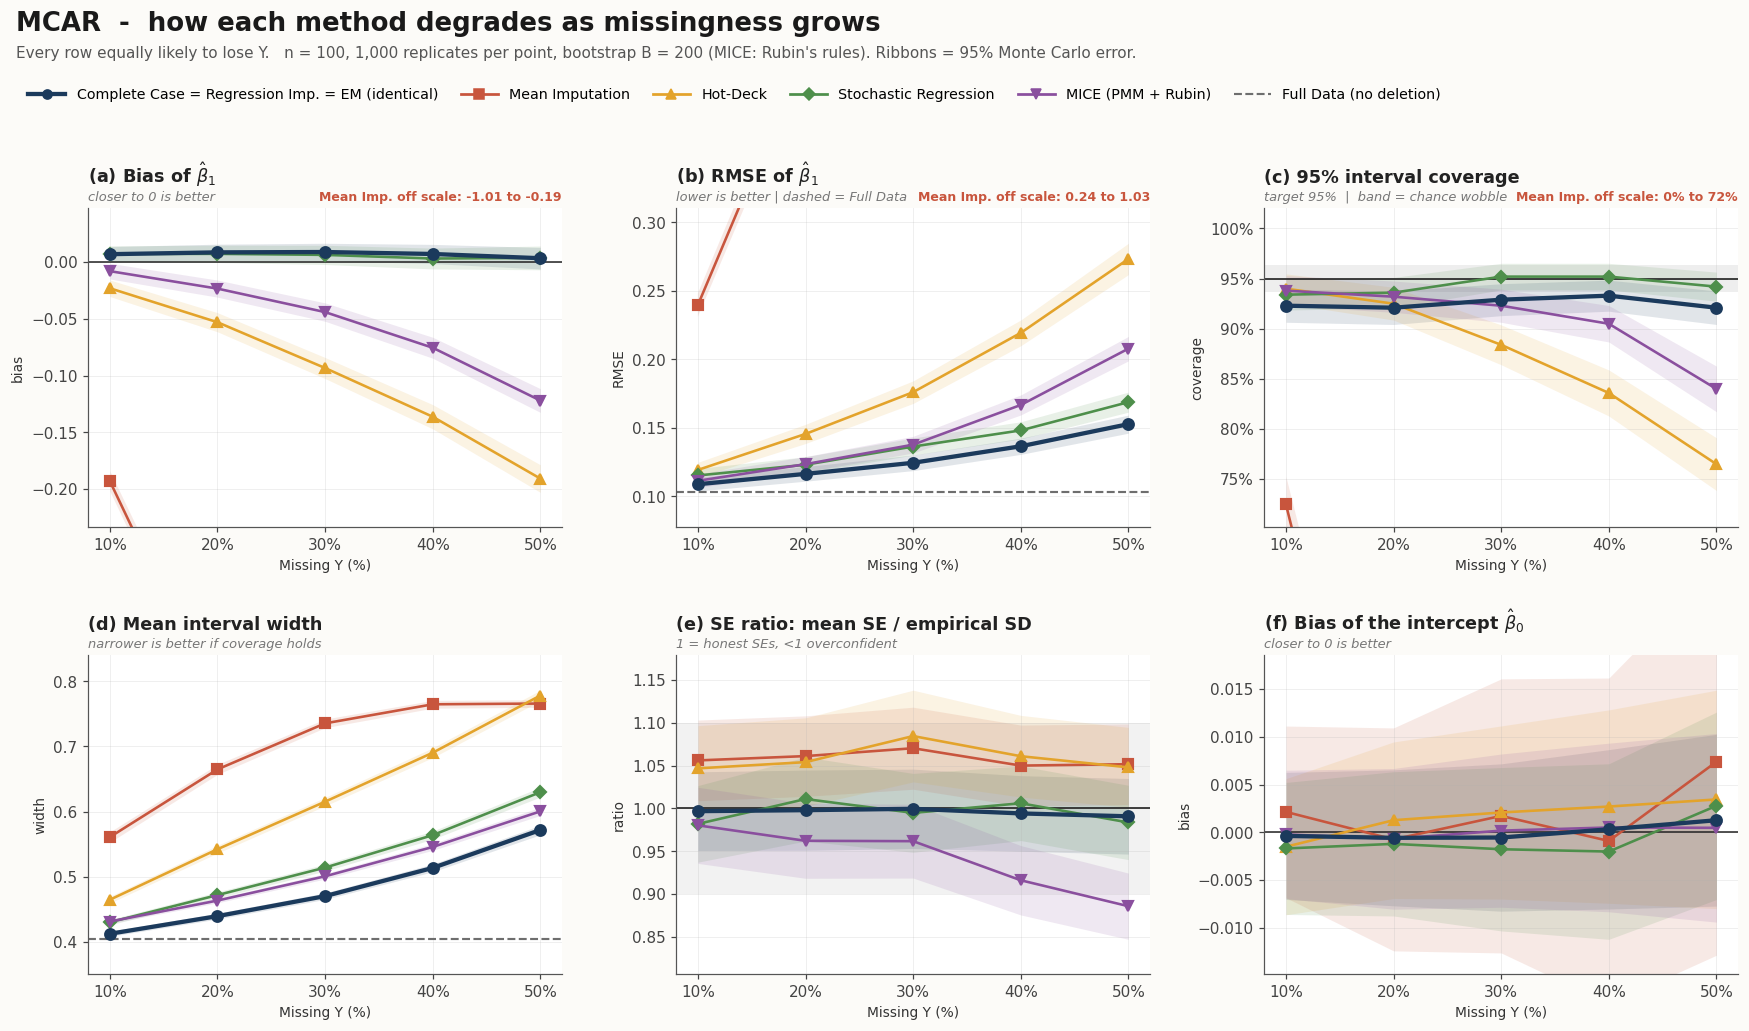

In [17]:
# 10.2  Dashboard (6 panels) for one mechanism
def severity_dashboard(mech, perf1, perf0, fname, fig_no):
    Rn = int(perf1[perf1["mechanism"] == mech]["R"].iloc[0])
    fig, axes = plt.subplots(2, 3, figsize=(16, 9.4), facecolor=FIG_BG)
    ax = axes.ravel()

    # (a) bias beta1
    draw_lines(ax[0], perf1, mech, "bias", "mc_se_bias"); ax[0].axhline(0, color="#222", lw=1)
    fit_ylim(ax[0], [perf1], [mech], "bias", "mc_se_bias", extras=[0]); note_offscale(ax[0], perf1, mech, "bias", "{:+.2f}")
    style_axes(ax[0], r"(a) Bias of $\hat\beta_1$", "closer to 0 is better", "bias")
    # (b) RMSE
    draw_lines(ax[1], perf1, mech, "rmse", "mc_se_rmse"); ax[1].axhline(full_ref(perf1, "rmse"), color=PAL["Full Data"], ls="--", lw=1.4)
    fit_ylim(ax[1], [perf1], [mech], "rmse", "mc_se_rmse", extras=[full_ref(perf1, "rmse")], lo_clip=0)
    note_offscale(ax[1], perf1, mech, "rmse", "{:.2f}")
    style_axes(ax[1], r"(b) RMSE of $\hat\beta_1$", "lower is better | dashed = Full Data", "RMSE")
    # (c) coverage
    band = 1.96 * np.sqrt(0.95 * 0.05 / Rn)
    ax[2].axhspan(0.95 - band, 0.95 + band, color="#999999", alpha=0.16, lw=0, zorder=0)
    ax[2].axhline(0.95, color="#222", lw=1.1, zorder=2)
    draw_lines(ax[2], perf1, mech, "coverage", "mc_se_cov", bounds=(0, 1))
    fit_ylim(ax[2], [perf1], [mech], "coverage", "mc_se_cov", extras=[0.95 - band, 0.95 + band, 1.0], hi_clip=1.02, lo_clip=0)
    note_offscale(ax[2], perf1, mech, "coverage", "{:.0%}")
    ax[2].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    style_axes(ax[2], "(c) 95% interval coverage", "target 95%  |  band = chance wobble", "coverage")
    # (d) width
    draw_lines(ax[3], perf1, mech, "width", "mc_se_width"); ax[3].axhline(full_ref(perf1, "width"), color=PAL["Full Data"], ls="--", lw=1.4)
    fit_ylim(ax[3], [perf1], [mech], "width", "mc_se_width", extras=[full_ref(perf1, "width")])
    note_offscale(ax[3], perf1, mech, "width", "{:.2f}")
    style_axes(ax[3], "(d) Mean interval width", "narrower is better if coverage holds", "width")
    # (e) SE ratio
    ax[4].axhspan(0.9, 1.1, color="#999999", alpha=0.12, lw=0, zorder=0); ax[4].axhline(1.0, color="#222", lw=1.1, zorder=2)
    draw_lines(ax[4], perf1, mech, "se_ratio", "mc_se_se_ratio")
    fit_ylim(ax[4], [perf1], [mech], "se_ratio", "mc_se_se_ratio", extras=[0.9, 1.1])
    note_offscale(ax[4], perf1, mech, "se_ratio", "{:.2f}")
    style_axes(ax[4], "(e) SE ratio: mean SE / empirical SD", "1 = honest SEs, <1 overconfident", "ratio")
    # (f) intercept bias
    draw_lines(ax[5], perf0, mech, "bias", "mc_se_bias"); ax[5].axhline(0, color="#222", lw=1)
    fit_ylim(ax[5], [perf0], [mech], "bias", "mc_se_bias", extras=[0]); note_offscale(ax[5], perf0, mech, "bias", "{:+.2f}")
    style_axes(ax[5], r"(f) Bias of the intercept $\hat\beta_0$", "closer to 0 is better", "bias")

    fig.suptitle(f"{mech}  -  how each method degrades as missingness grows", x=0.012, y=0.992, ha="left",
                 fontsize=17, fontweight="bold", color="#1a1a1a")
    fig.text(0.012, 0.947, f"{MECH_DESC[mech]}   n = 100, {Rn:,} replicates per point, bootstrap B = {BOOT_B} (MICE: Rubin's rules). "
             "Ribbons = 95% Monte Carlo error.", fontsize=10, color="#555555", ha="left")
    fig.legend(handles=legend_handles(), loc="upper left", bbox_to_anchor=(0.012, 0.930), ncol=6, frameon=False,
               fontsize=9.3, handlelength=2.6, columnspacing=1.6)
    fig.tight_layout(rect=[0, 0, 1, 0.905], h_pad=2.2, w_pad=1.8)
    path = f"{OUT}/figures/fig{fig_no}_severity_{mech}.png"
    fig.savefig(path, dpi=200, facecolor=fig.get_facecolor()); plt.show()
    return path

import matplotlib.ticker
FIGS = []
FIGS.append(severity_dashboard("MCAR", perf1, perf0, None, 5))

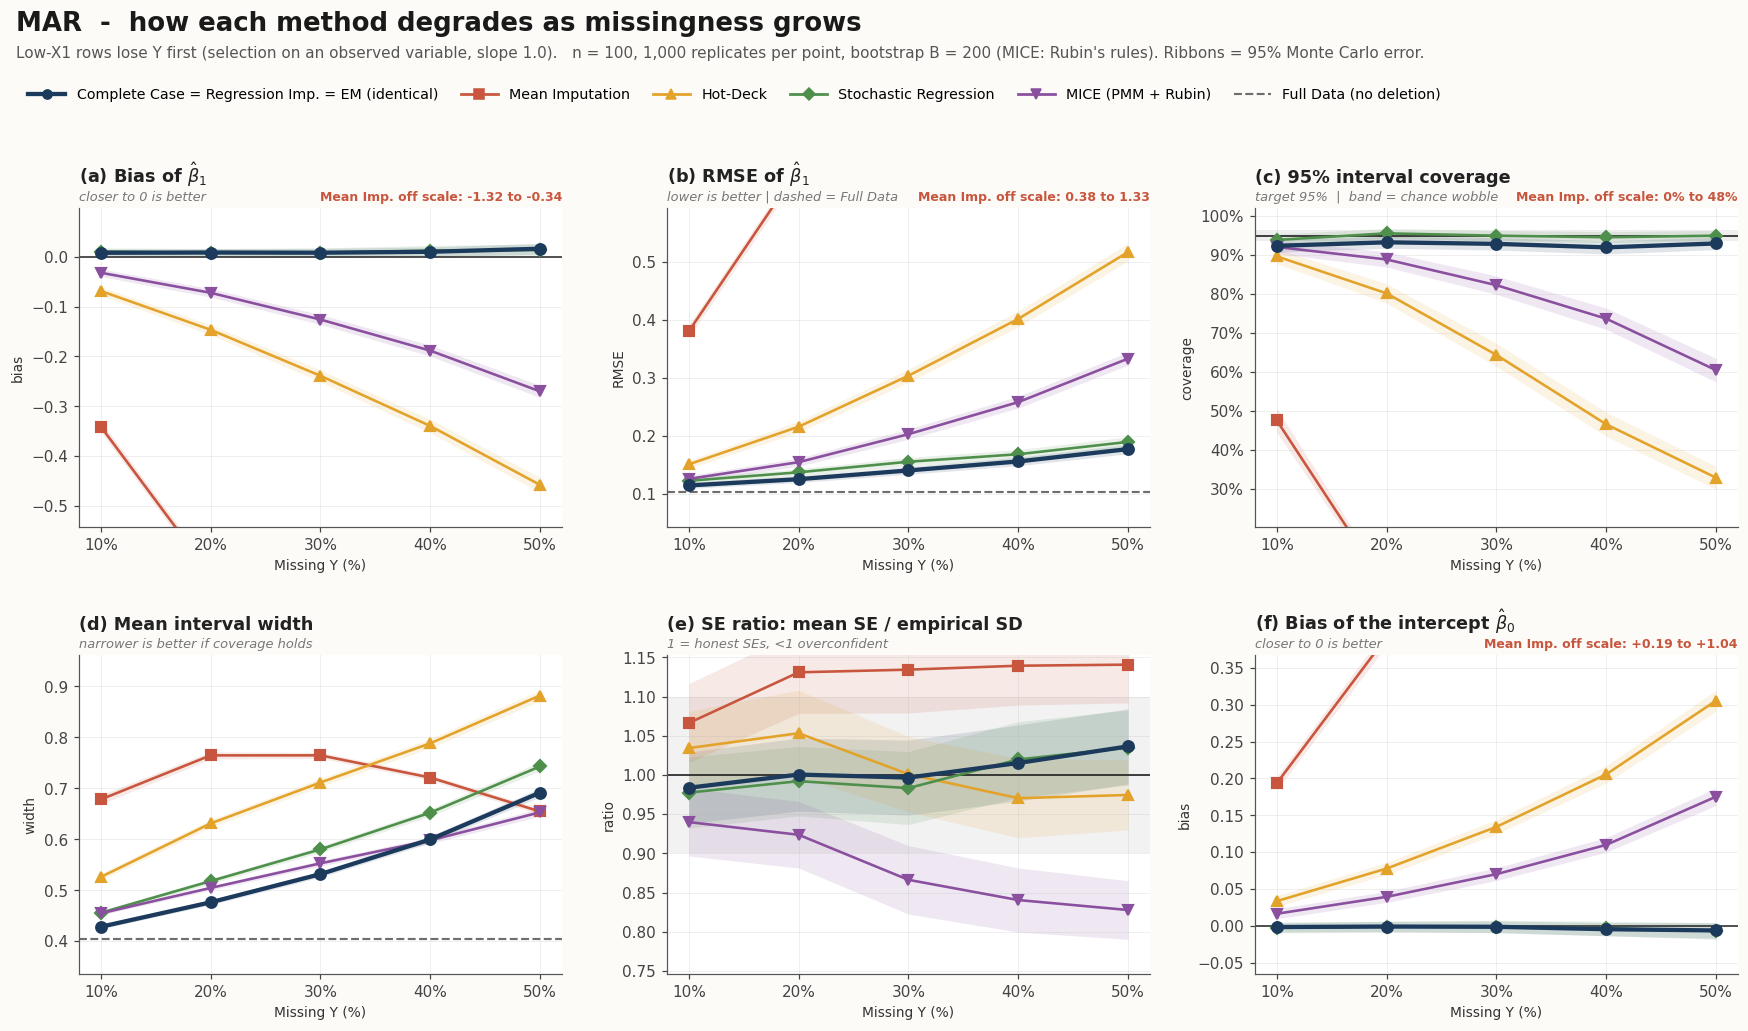

In [18]:
# 10.3  MAR dashboard
FIGS.append(severity_dashboard("MAR", perf1, perf0, None, 6))

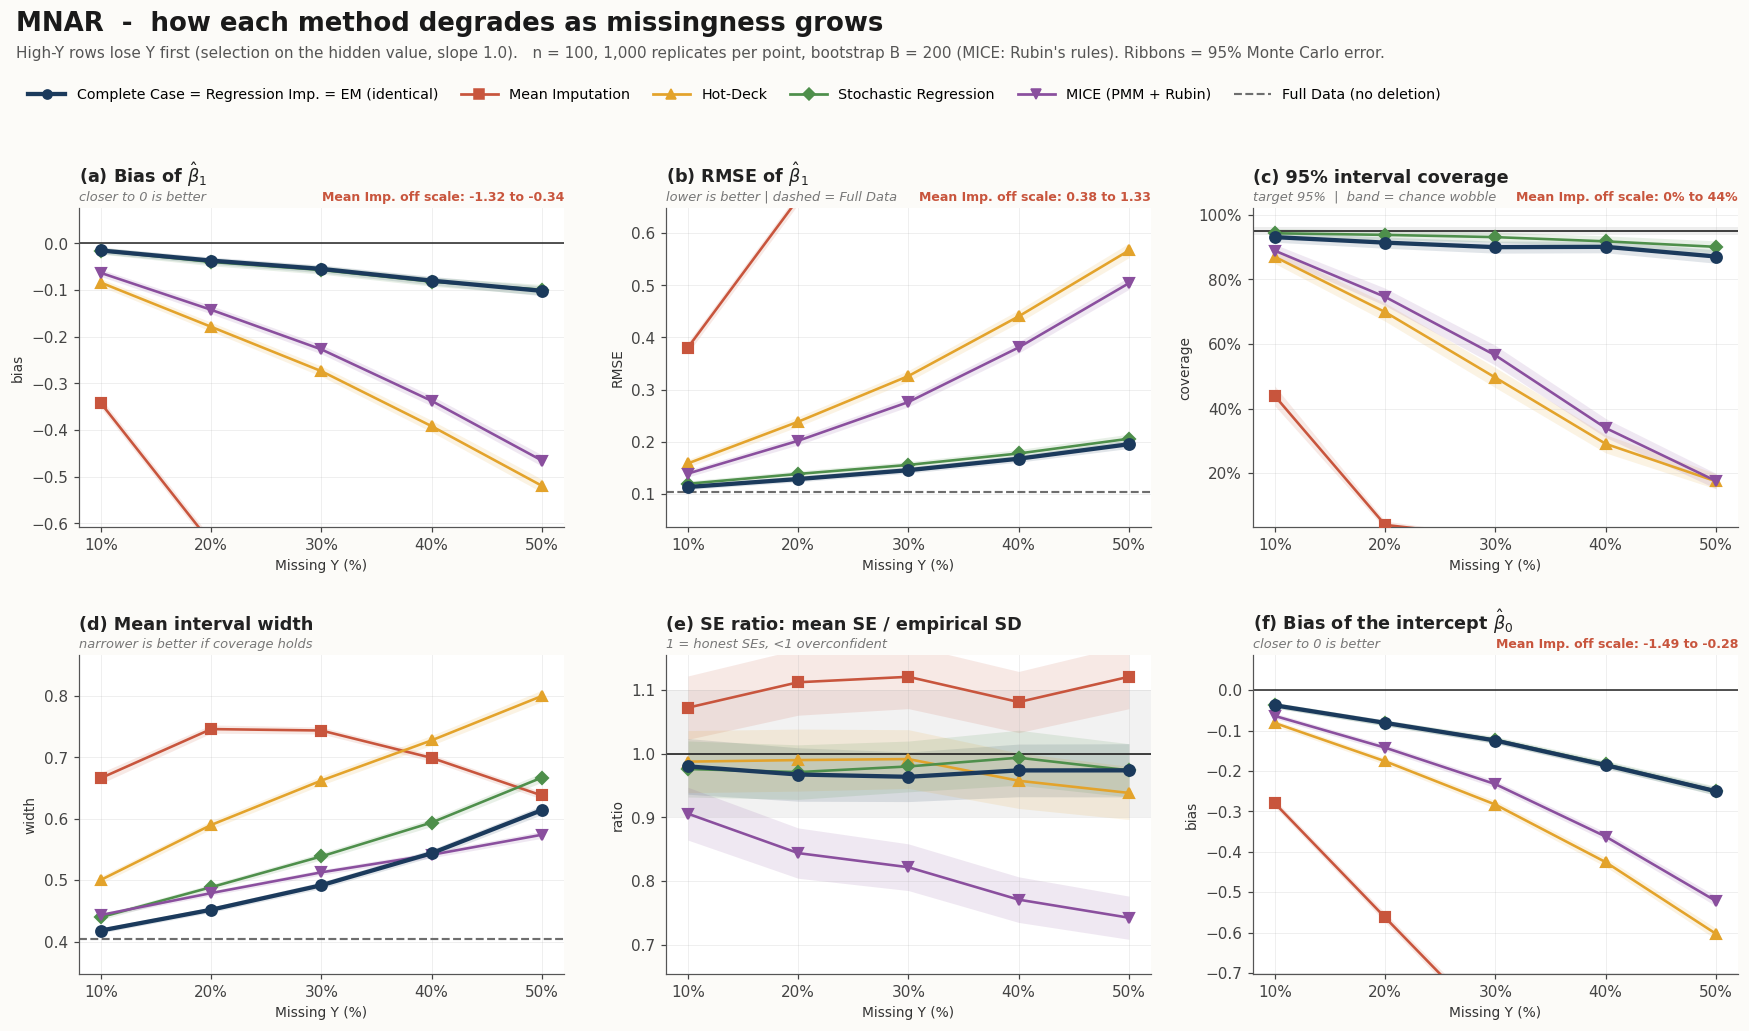

In [19]:
# 10.4  MNAR dashboard
FIGS.append(severity_dashboard("MNAR", perf1, perf0, None, 7))

### 10.5 Headline figure: coverage of the 95% interval, all mechanisms side by side
The one figure that summarises the whole study. Full 0–100% scale, nothing clipped, same colours and ribbons as above.

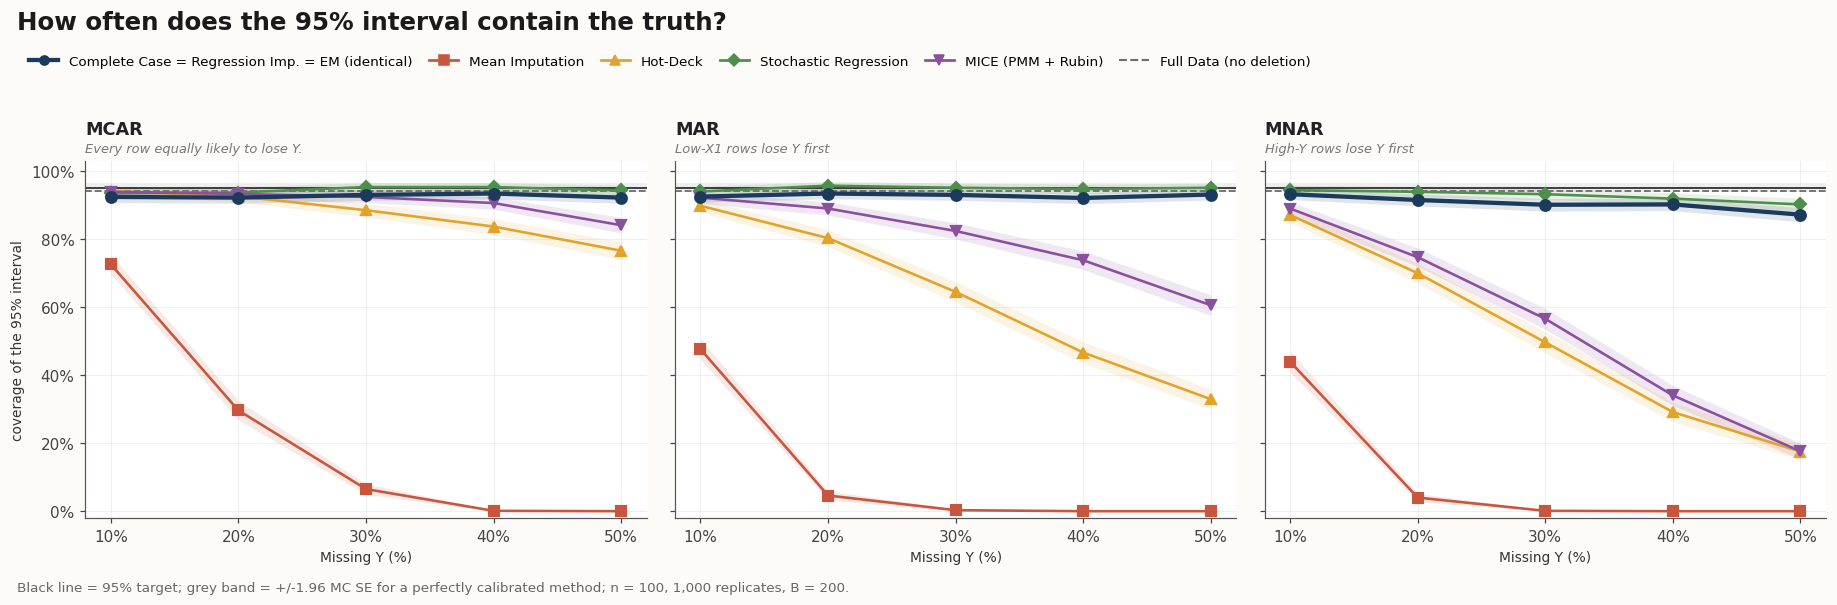

PASS  [10] Four severity figures written (3 dashboards + headline coverage)  ->  4 files


In [20]:
# 10.5  Headline coverage figure (1 x 3, full scale)
def headline_coverage(perf1, mechs, fname, title, fig_no):
    Rn = int(perf1[perf1["mechanism"] == mechs[0]]["R"].iloc[0]); band = 1.96 * np.sqrt(0.95 * 0.05 / Rn)
    fig, axes = plt.subplots(1, len(mechs), figsize=(5.6 * len(mechs), 5.4), sharey=True, facecolor=FIG_BG)
    axes = np.atleast_1d(axes)
    for a, mech in zip(axes, mechs):
        a.axhspan(0.95 - band, 0.95 + band, color="#999999", alpha=0.16, lw=0, zorder=0)
        a.axhline(0.95, color="#222", lw=1.1, zorder=2)
        a.axhline(full_ref(perf1, "coverage"), color=PAL["Full Data"], ls="--", lw=1.2, zorder=2)
        draw_lines(a, perf1, mech, "coverage", "mc_se_cov", bounds=(0, 1))
        a.set_ylim(-0.02, 1.03); a.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
        style_axes(a, mech, MECH_DESC[mech].split(" (")[0], "coverage of the 95% interval" if a is axes[0] else None)
    fig.suptitle(title, x=0.012, y=0.99, ha="left", fontsize=16, fontweight="bold", color="#1a1a1a")
    fig.legend(handles=legend_handles(), loc="upper left", bbox_to_anchor=(0.012, 0.935), ncol=6, frameon=False, fontsize=8.8,
               handlelength=2.2, columnspacing=1.2)
    fig.text(0.012, 0.012, f"Black line = 95% target; grey band = +/-1.96 MC SE for a perfectly calibrated method; n = 100, "
             f"{Rn:,} replicates, B = {BOOT_B}.", fontsize=8.8, color="#666666")
    fig.tight_layout(rect=[0, 0.03, 1, 0.90], w_pad=1.5)
    path = f"{OUT}/figures/fig{fig_no}_{fname}.png"
    fig.savefig(path, dpi=200, facecolor=fig.get_facecolor()); plt.show()
    return path

FIGS.append(headline_coverage(perf1, tb.MAIN_MECHANISMS, "coverage_headline",
                              "How often does the 95% interval contain the truth?", 8))
record("10", "Four severity figures written (3 dashboards + headline coverage)", all(os.path.exists(p) for p in FIGS), f"{len(FIGS)} files")

---
## Section 11 · Report card and export

### 11.1 Report card
Every check from this notebook in one table. Integrity checks (Sections 8, 11) should **all** say PASS. A FAIL in Section 9.5 is a *finding to discuss*, not necessarily a bug — tell me about it.

In [26]:
# 11.1  Report card
report = pd.DataFrame(TESTS)
report.to_csv(f"{OUT}/results/sanity_tests_stage2.csv", index=False)
pd.set_option("display.max_colwidth", 130, "display.width", 240)
display(report)
n_pass, n_fail = int((report["result"] == "PASS").sum()), int((report["result"] == "FAIL").sum())
integrity_fail = int(((report["result"] == "FAIL") & (~report["section"].isin(["9.5"]))).sum())
print(f"\n{n_pass} checks passed, {n_fail} failed.")
if n_fail == 0:
    print("STAGE 2 STATUS: ALL CHECKS PASSED - READY FOR PART 2B")
elif integrity_fail == 0:
    print("STAGE 2 STATUS: data integrity fine; some expectation checks (9.5) failed - please send me the table.")
else:
    print("STAGE 2 STATUS: INTEGRITY CHECK FAILED - do not use these results; send me the table.")

,section,check,result,detail
0,8,Toolbox is byte-identical to the Stage 1 toolbox (SHA-256),PASS,
1,8,"Protocol constants are the agreed ones (n=100, 10-50%, 7 methods, m=20, k=5, seed 42, slopes 1.0/0.5)",PASS,
2,8,A replicate is exactly reproducible (same inputs -> identical rows),PASS,
3,8,Main run produces 106 rows per replicate,PASS,106
4,8.5,Row count = 1000 replicates x 106 rows,PASS,"106,000 rows"
5,8.5,Every condition (mechanism x severity x method) has every replicate exactly once,PASS,106 conditions x 1000
6,8.5,"No missing values in estimates, SEs or interval limits",PASS,
7,8.5,All SEs and interval widths are positive,PASS,
8,8.5,n_missing equals the severity level in every row (exact deletion),PASS,
9,8.5,"Complete Case = Regression Imputation = EM (all coefficients, SEs and intervals)",PASS,max difference 1.6e-07



24 checks passed, 0 failed.
STAGE 2 STATUS: ALL CHECKS PASSED - READY FOR PART 2B


### 11.2 Package everything and download
Creates **`part2A_stage2_outputs.zip`** and starts the download (a copy also goes to your Drive folder). If your browser blocks the download, open the 📁 file panel and download it from there.

| Folder | Contents |
|---|---|
| `data/` | **`raw_replicates.csv`** (every replicate × mechanism × severity × method, incl. Full Data) and `raw_replicates_mnar_mild.csv` — **this is what Part 2B loads** |
| `results/` | **`summary_by_condition.csv`** (all measures with MC SE), `summary_all_coefficients.csv`, MNAR_mild summaries, `sanity_tests_stage2.csv`, and `tables/` (every table shown above, as CSV) |
| `figures/` | Figures 5–9 (PNG, 200 dpi) |
| `code/` | `sim_toolbox.py` |
| top level | `README_stage2.txt`, `config_and_environment.json` |

In [27]:
# 11.2  Export -> zip -> download
raw.to_csv(f"{OUT}/data/raw_replicates.csv", index=False, float_format="%.10g")
if HAVE_MILD:
    raw_mild.to_csv(f"{OUT}/data/raw_replicates_mnar_mild.csv", index=False, float_format="%.10g")
shutil.copy("sim_toolbox.py", f"{OUT}/code/sim_toolbox.py")

config = {
    "stage": "Part 2A - Stage 2", "run_date": time.strftime("%Y-%m-%d %H:%M"),
    "master_seed": tb.MASTER_SEED, "n": tb.N, "true_beta": list(tb.BETA_TRUE), "severity_levels": tb.SEVERITY_LEVELS,
    "mechanisms": {k: tb.MECH_SPECS[k] for k in tb.MECH_SPECS}, "methods": tb.METHODS,
    "mice_m": tb.MICE_M, "pmm_k": tb.PMM_K, "em_tol": tb.EM_TOL,
    "run_settings": {"R_TARGET": R_TARGET, "CHUNK": CHUNK, "BOOT_B": BOOT_B, "N_JOBS_used": N_JOBS_USED,
                     "RUN_MILD": RUN_MILD, "replicates_main": R, "replicates_mild": int(raw_mild["rep"].nunique()) if HAVE_MILD else 0},
    "toolbox_sha256": TOOLBOX_SHA, "timing": TIMING, "speed_test": bench.round(3).to_dict(orient="records"),
    "checks": {"passed": n_pass, "failed": n_fail, "failed_integrity": integrity_fail},
    "environment": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                    "scipy": scipy.__version__, "matplotlib": matplotlib.__version__},
}
json.dump(config, open(f"{OUT}/config_and_environment.json", "w"), indent=2, default=str)

readme = f"""MISSING DATA ANALYSIS - PART 2A (SEVERITY ANALYSIS) - STAGE 2 OUTPUTS
Author: Purbasa Bhaduri
Run date: {time.strftime('%Y-%m-%d %H:%M')}

Design: n=100, Y = 5 + 2*X1 - 1.5*X2 + X3 + e; severity 10-50% (exactly k values deleted);
MCAR, MAR (slope 1.0 on -z(X1)), MNAR (slope 1.0 on z(Y)){' + MNAR_mild (slope 0.5)' if HAVE_MILD else ''};
7 methods + Full Data reference; bootstrap B={BOOT_B} (MICE: m=20 proper PMM, Rubin's rules, Barnard-Rubin df).
Replicates: {R} per mechanism (paired: the same complete datasets are used for every mechanism and severity).

Contents
  data/raw_replicates.csv                 one row per replicate x mechanism x severity x method (incl. Full Data)
  data/raw_replicates_mnar_mild.csv       same, for the MNAR_mild sensitivity run (if run)
  results/summary_by_condition.csv        beta1: bias, emp_sd, rmse, avg_se, se_ratio, coverage, width, miss_low/high, each with MC SE
  results/summary_all_coefficients.csv    bias / emp_sd / rmse for beta0..beta3 (coverage exists only for beta1)
  results/summary_mnar_mild_b0_b1.csv     MNAR_mild bias / sd / rmse for beta0, beta1 (if run)
  results/summary_by_condition_mnar_mild.csv
  results/tables/                         every table shown in the notebook (estimate (MC SE)), as CSV
  results/sanity_tests_stage2.csv         report card: {n_pass} passed, {n_fail} failed
  figures/fig5..fig9                      MCAR / MAR / MNAR dashboards, headline coverage, MNAR strength sensitivity
  code/sim_toolbox.py                     the Stage 1 toolbox (SHA-256 {TOOLBOX_SHA[:16]}...)
  config_and_environment.json             settings, timing, versions

Next: Part 2B loads data/raw_replicates.csv and results/summary_by_condition.csv.
"""
open(f"{OUT}/README_stage2.txt", "w").write(readme)

zip_base = "part2A_stage2_outputs"
shutil.make_archive(zip_base, "zip", ".", OUT)
size_mb = os.path.getsize(zip_base + ".zip") / 1e6
print(f"Created {zip_base}.zip ({size_mb:.1f} MB)")
if STORE != "local_store":
    shutil.copy(zip_base + ".zip", f"{STORE}/{zip_base}.zip"); print("Copy saved to Drive:", f"{STORE}/{zip_base}.zip")
for root, _, files_ in os.walk(OUT):
    for fn in sorted(files_):
        p = os.path.join(root, fn); print(f"  {p[len(OUT)+1:]:<58s}{os.path.getsize(p)/1024:>10.1f} KB")
try:
    from google.colab import files
    files.download(zip_base + ".zip")
except Exception:
    print("\n(Not in Colab, or the download was blocked: the zip is in the working folder.)")

Created part2A_stage2_outputs.zip (6.4 MB)
Copy saved to Drive: /content/drive/MyDrive/MissingData_Part2A_Stage2/part2A_stage2_outputs.zip
  README_stage2.txt                                                1.6 KB
  config_and_environment.json                                      1.7 KB
  code/sim_toolbox.py                                             17.5 KB
  figures/fig5_severity_MCAR.png                                 617.0 KB
  figures/fig6_severity_MAR.png                                  664.2 KB
  figures/fig7_severity_MNAR.png                                 705.1 KB
  figures/fig8_coverage_headline.png                             351.1 KB
  results/sanity_tests_stage2.csv                                  2.2 KB
  results/summary_all_coefficients.csv                            82.0 KB
  results/summary_by_condition.csv                                31.4 KB
  results/tables/table_MAR_bias.csv                                0.6 KB
  results/tables/table_MAR_coverage.csv        

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## What to do next
1. Check that Section 12.1 says **ALL CHECKS PASSED** (or tell me exactly which row failed), and that the zip downloaded.
2. Come back with: **(a)** the report card, **(b)** the timing from Section 8.3 / 8.6, **(c)** anything that looked odd, and **(d)** the zip (or at least `data/raw_replicates.csv` and `results/summary_by_condition.csv`). Please also look at the three dashboards and the headline figure and tell me what *you* see before I tell you what I see.
3. Then I write **Part 2B**: paired mechanism comparisons, method rankings and heatmaps, breaking points (coverage < 90% / material bias), the method × mechanism interaction, SE calibration, and the *"which method when"* decision guide.

**Do not delete the Drive folder `MissingData_Part2A_Stage2`** until the whole project is finished: it lets you extend the study (for example to 2,000 replicates) without recomputing anything.